In [1]:
#Run the following code to print multiple outputs from a cell
get_ipython().ast_node_interactivity = 'all'

# Explanatory Visualizations

In the class on Profiling, we learned how to create basic visualizations using matplotlib. These were *exploratory* visualizations, intended to help us understand our data before building models.

Over the next 2 class sessions, we'll be looking at how to create *explanatory* visualizations, which are graphs intended to convey a message about your analysis. To do this, we will be using the `plotnine` package, which is based on the structure of `ggplot()` graphs from R.

In this first worksheet, we will cover the following topics:

* the structure of `ggplot()` commands
* how to create basic visualizations (e.g., histograms, boxplots, bar charts, & scatter plots)

In the next worksheet, we will look at how to polish your graphs with title, axis labels, customized graph elements, and annotations.

First, let's import the file, "dataBeatport.csv", and save it in a variable called `df`. 

In [2]:
import pandas as pd
df = pd.read_csv("dataBeatport.csv")
df

,genre,enteredCharts,twitterFollowers,artistSongs,labelSongs,daysAfterRelease
0,Deep House,0,1820,105,304,2
1,House,0,389,89,34,20
2,Trance,1,25141,231,781,23
3,Deep House,0,233,28,91,14
4,Deep House,0,168,104,121,16
...,...,...,...,...,...,...
11965,Deep House,0,567,159,40,23
11966,Techno,0,196,23,9,2
11967,Electro House,0,168,117,1319,2
11968,Electro House,0,1858,41,1319,2


## Structure of `ggplot()`

The graphs we will be building with `ggplot()` come from the `plotnine` package. Let's first import the package:

In [3]:
# imports everything from plotnine
from plotnine import *

Graphs in `ggplot()` are built in layers. Let's take a look at a basic scatter plot and break it down layer by layer:

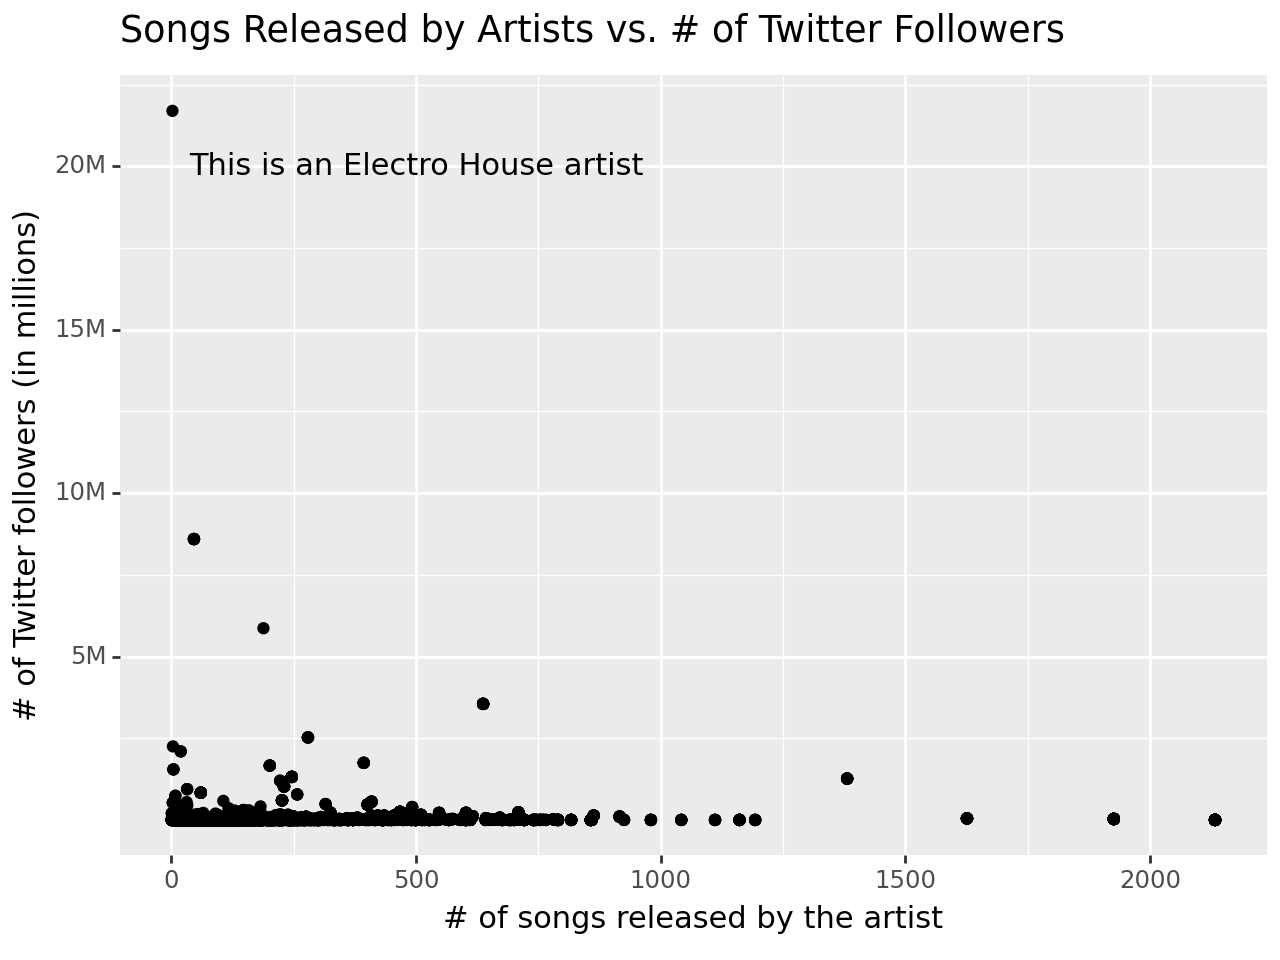

<Figure Size: (640 x 480)>

In [4]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")) +
   geom_point() +
   labs(title = "Songs Released by Artists vs. # of Twitter Followers",
       x = "# of songs released by the artist",
       y = "# of Twitter followers (in millions)") +
   scale_y_continuous(breaks = [5000000, 10000000, 15000000, 20000000],
       labels = ["5M", "10M", "15M", "20M"]) +
   annotate("text", x = 500, y = 20000000, label = "This is an Electro House artist"))

As you can see, each layer is separated with a `+` symbol. To avoid typing `\` to break each line, if you contain the entire code in `()`s, you can continue on to separate lines.

### 1. Aesthetic Mappings

Run the following code to see what the first layer does:

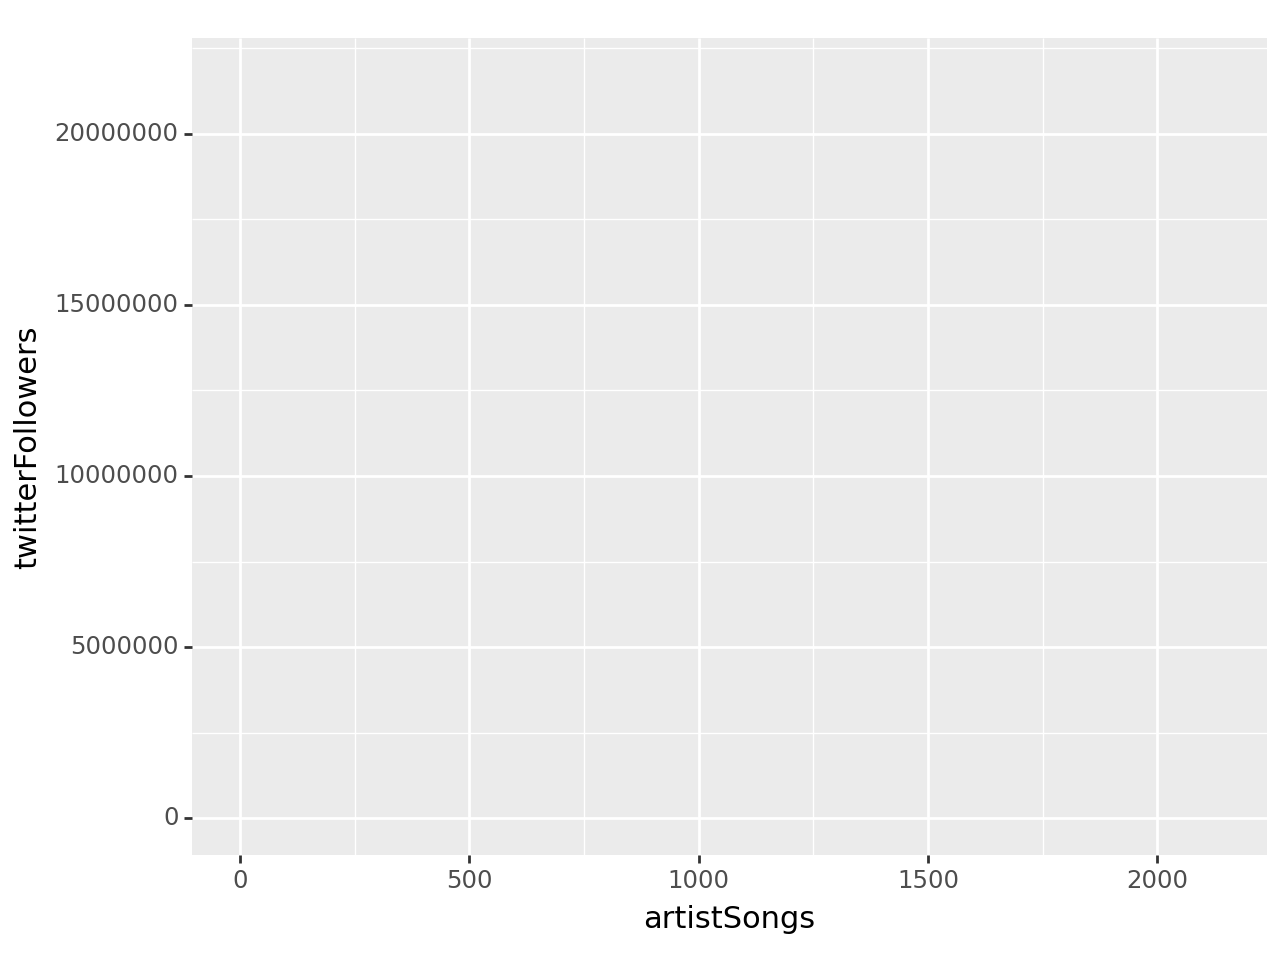

<Figure Size: (640 x 480)>

In [5]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")))

In the first layer, you set up the graph, stating which variables map to which element of your graph. Here, we're indicating which variables will be on the x- and y-axes.

### 2. Geometric Function

In the next layer, we indicate the type of graph we'll be drawing. Here, we've indicated that we want to draw points on our graph (i.e., a scatter plot):

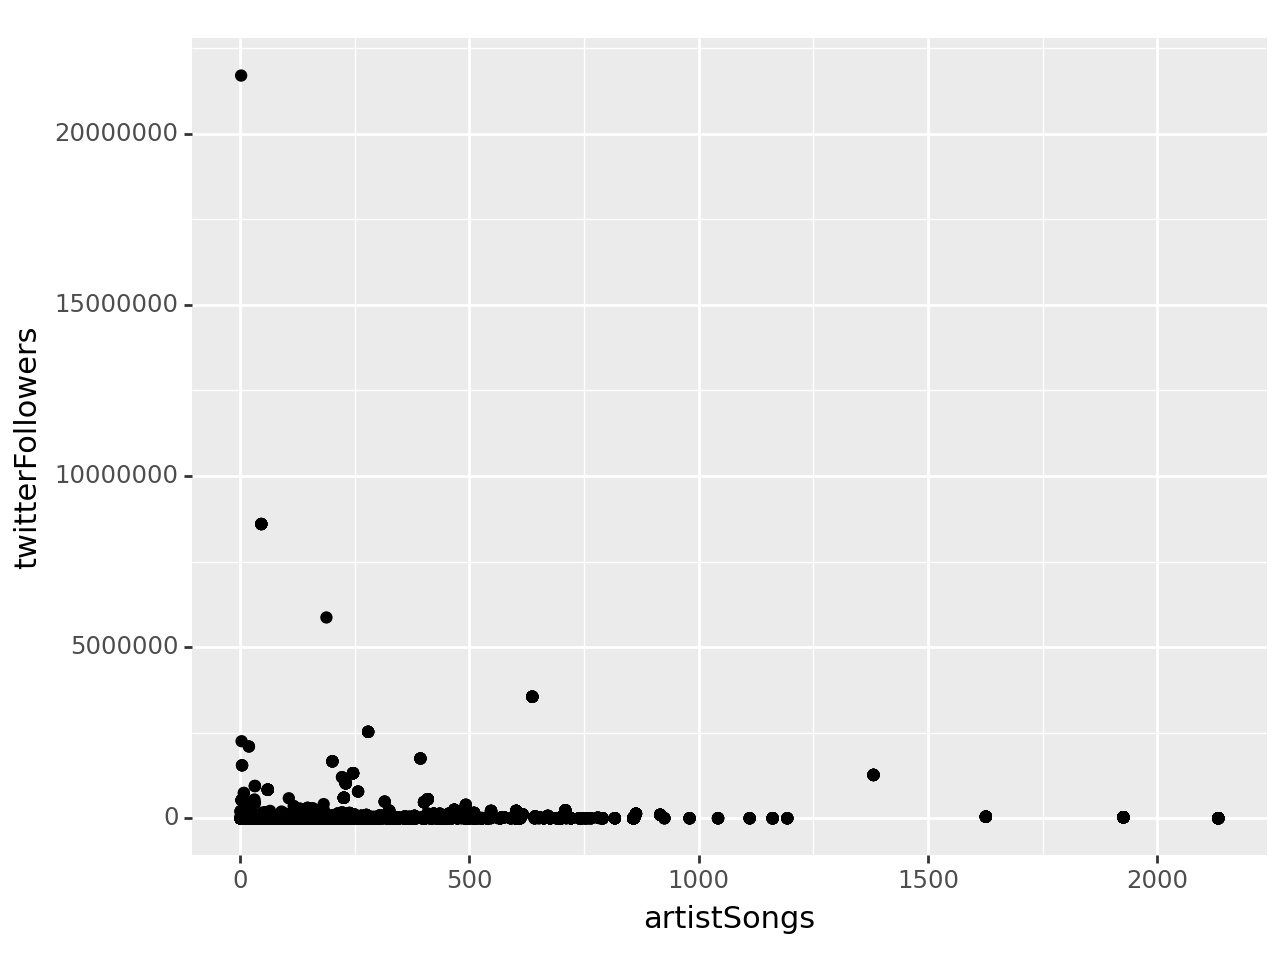

<Figure Size: (640 x 480)>

In [6]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")) +
   geom_point())

The main types of graphs you can create are:

* `geom_point()` - scatter plot
* `geom_histogram()` - histogram
* `geom_density()` - density histogram
* `geom_boxplot()` - boxplot
* `geom_bar()` - bar chart
* `geom_line()` - line graph
* `geom_smooth()` - smoothed line (e.g., a regression line)

### 3. Labels and Scales

Next, we can customize the graph with labels using `lab()`:

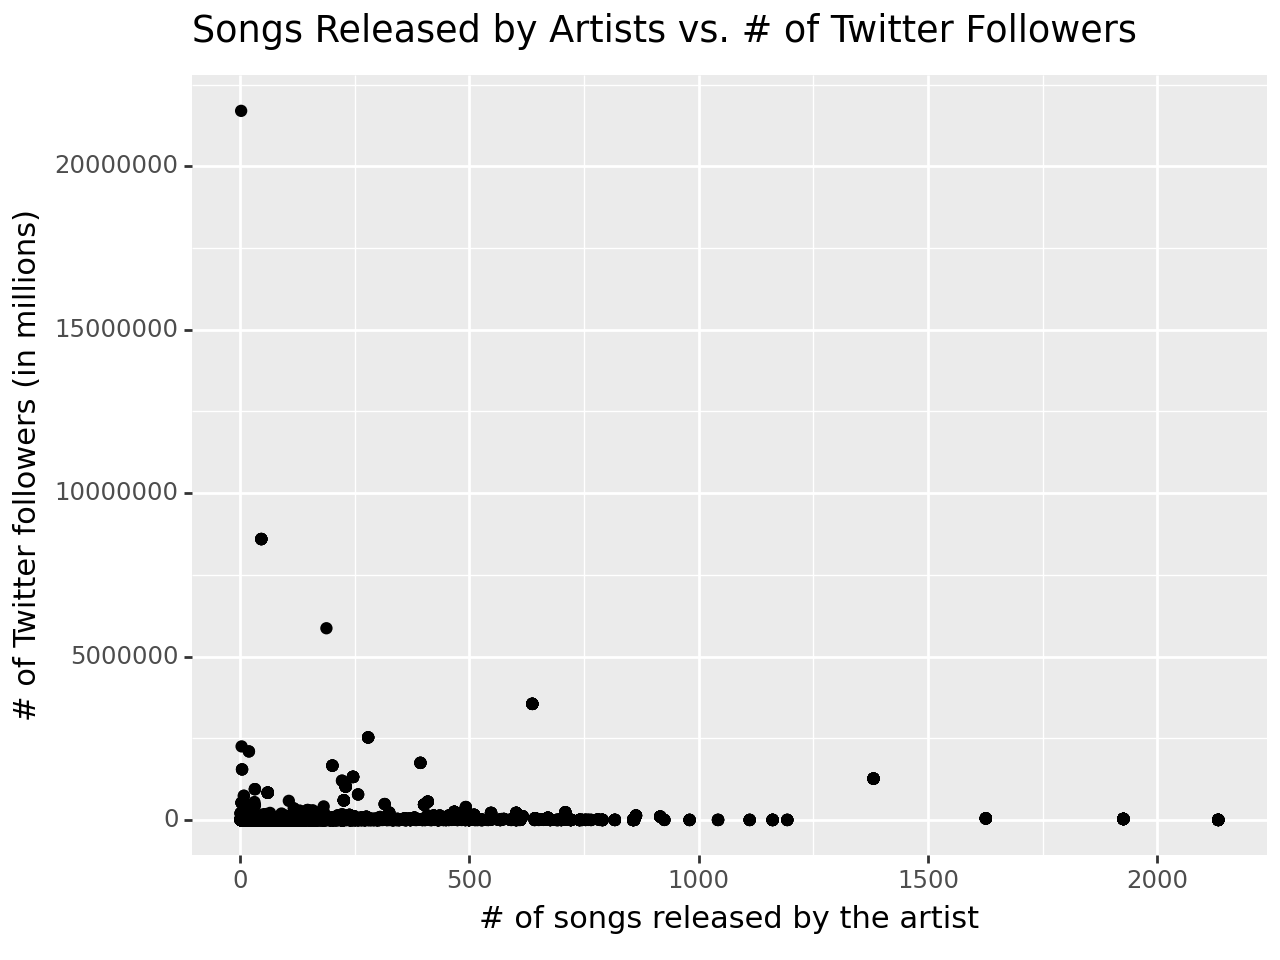

<Figure Size: (640 x 480)>

In [7]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")) +
   geom_point() +
   labs(title = "Songs Released by Artists vs. # of Twitter Followers",
       x = "# of songs released by the artist",
       y = "# of Twitter followers (in millions)"))

You can also customize your axes using `scales...()`. Here, we're adjusting the y-axis break points and labels:

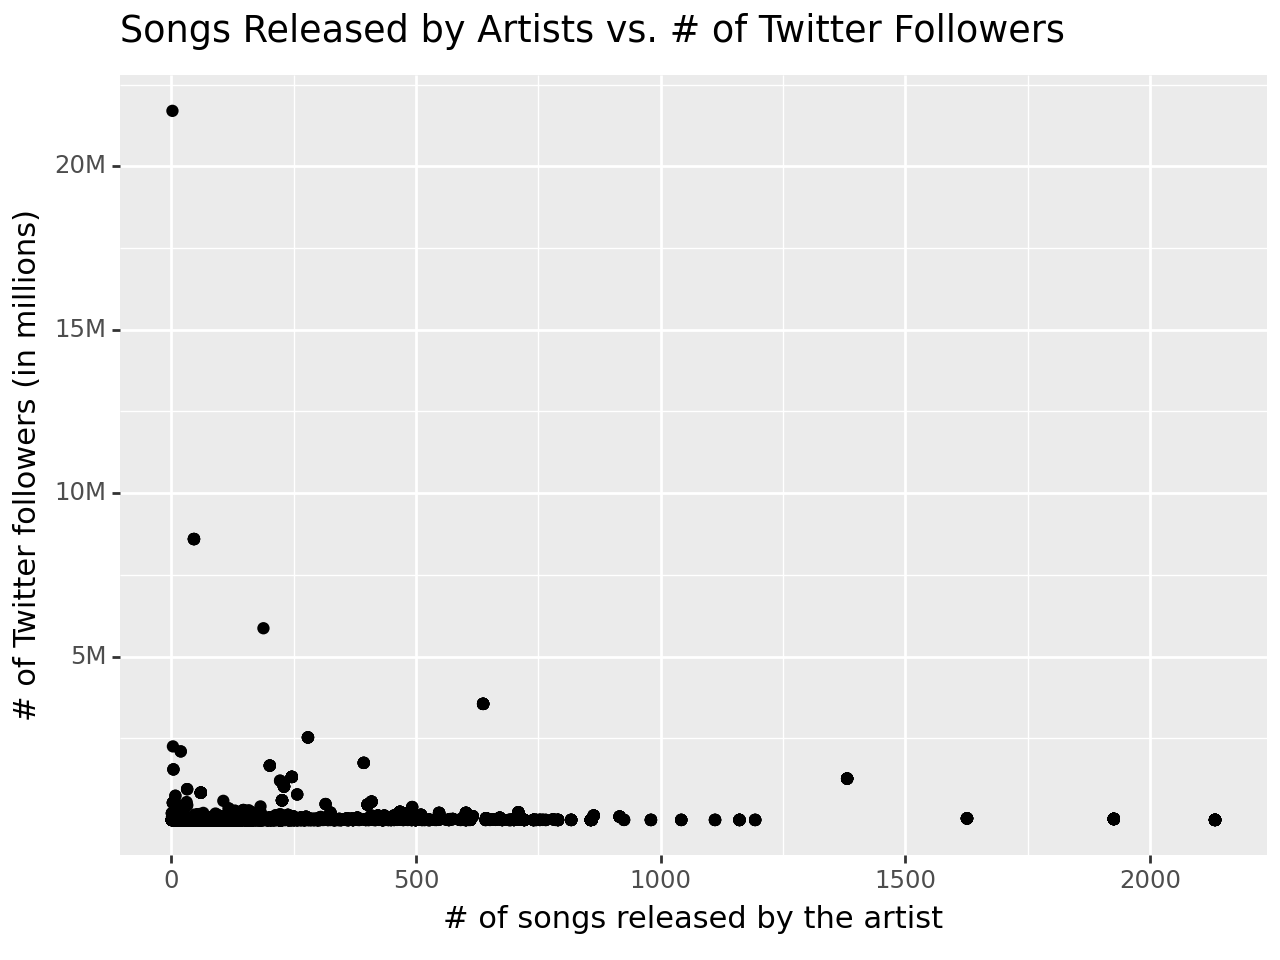

<Figure Size: (640 x 480)>

In [8]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")) +
   geom_point() +
   labs(title = "Songs Released by Artists vs. # of Twitter Followers",
       x = "# of songs released by the artist",
       y = "# of Twitter followers (in millions)") +
   scale_y_continuous(breaks = [5000000, 10000000, 15000000, 20000000],
       labels = ["5M", "10M", "15M", "20M"]))

### 4. Annotations

Finally, you can add annotations onto the graph. Here, we're adding some text to call out the outlier:

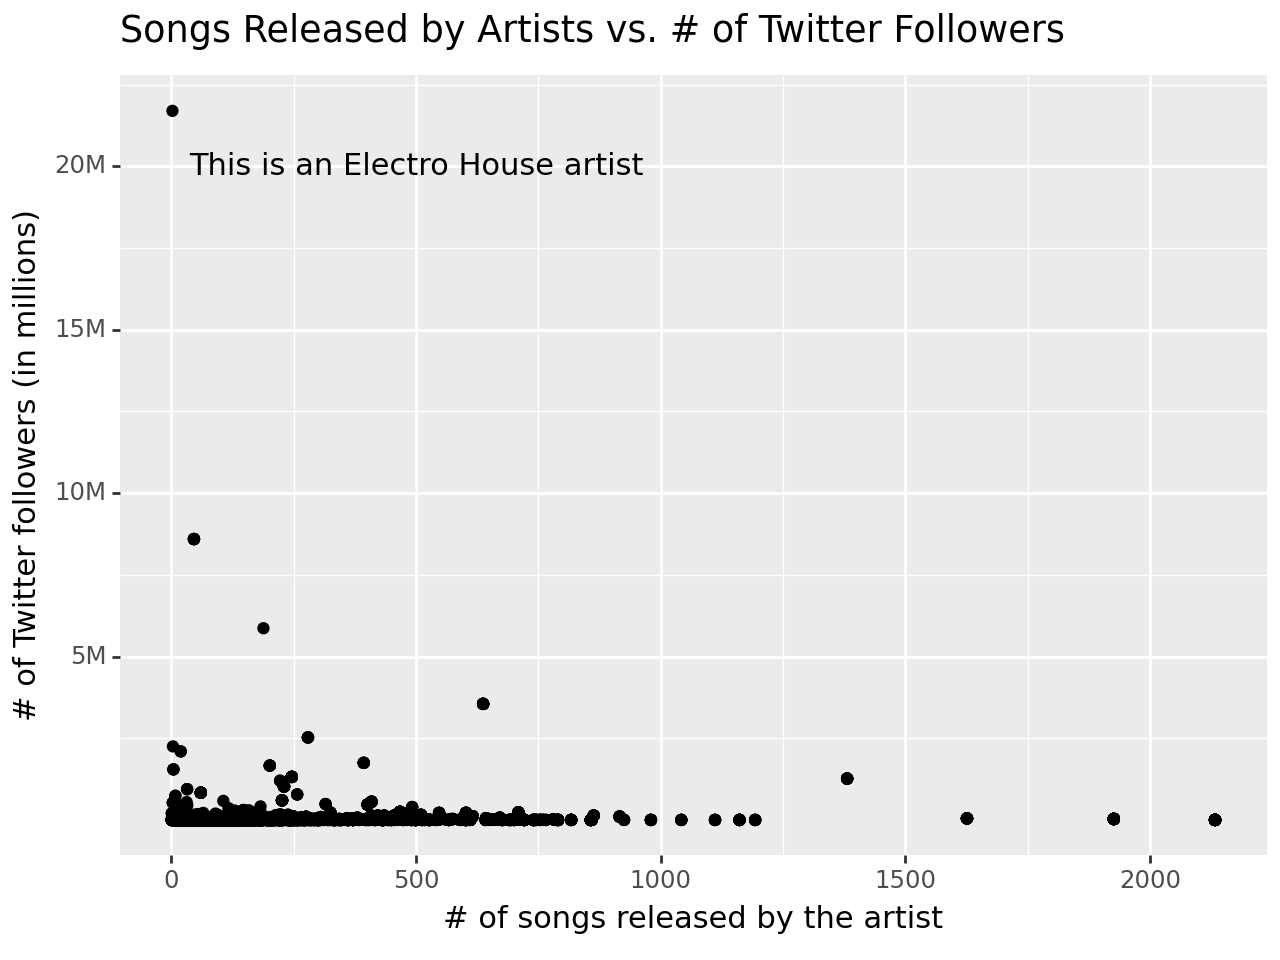

<Figure Size: (640 x 480)>

In [9]:
(ggplot(df, aes(x = "artistSongs", y = "twitterFollowers")) +
   geom_point() +
   labs(title = "Songs Released by Artists vs. # of Twitter Followers",
       x = "# of songs released by the artist",
       y = "# of Twitter followers (in millions)") +
   scale_y_continuous(breaks = [5000000, 10000000, 15000000, 20000000],
       labels = ["5M", "10M", "15M", "20M"]) +
   annotate("text", x = 500, y = 20000000, label = "This is an Electro House artist"))

There are a number of different annotations you can add to the graph, including "text", "point", and "segment" (which is a line).

## Basic Graphs

### Graphs for Numeric Data

Remember, the 2 most common graphs to display numeric data are ***histograms*** and ***boxplots***. If you want to see 2 numeric variables compared to each other, a ***scatter plot*** is best.

#### Histograms

Let's look at a histogram of the "twitterFollowers" variable:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/stats/stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 50'. Pick better value with 'binwidth'.


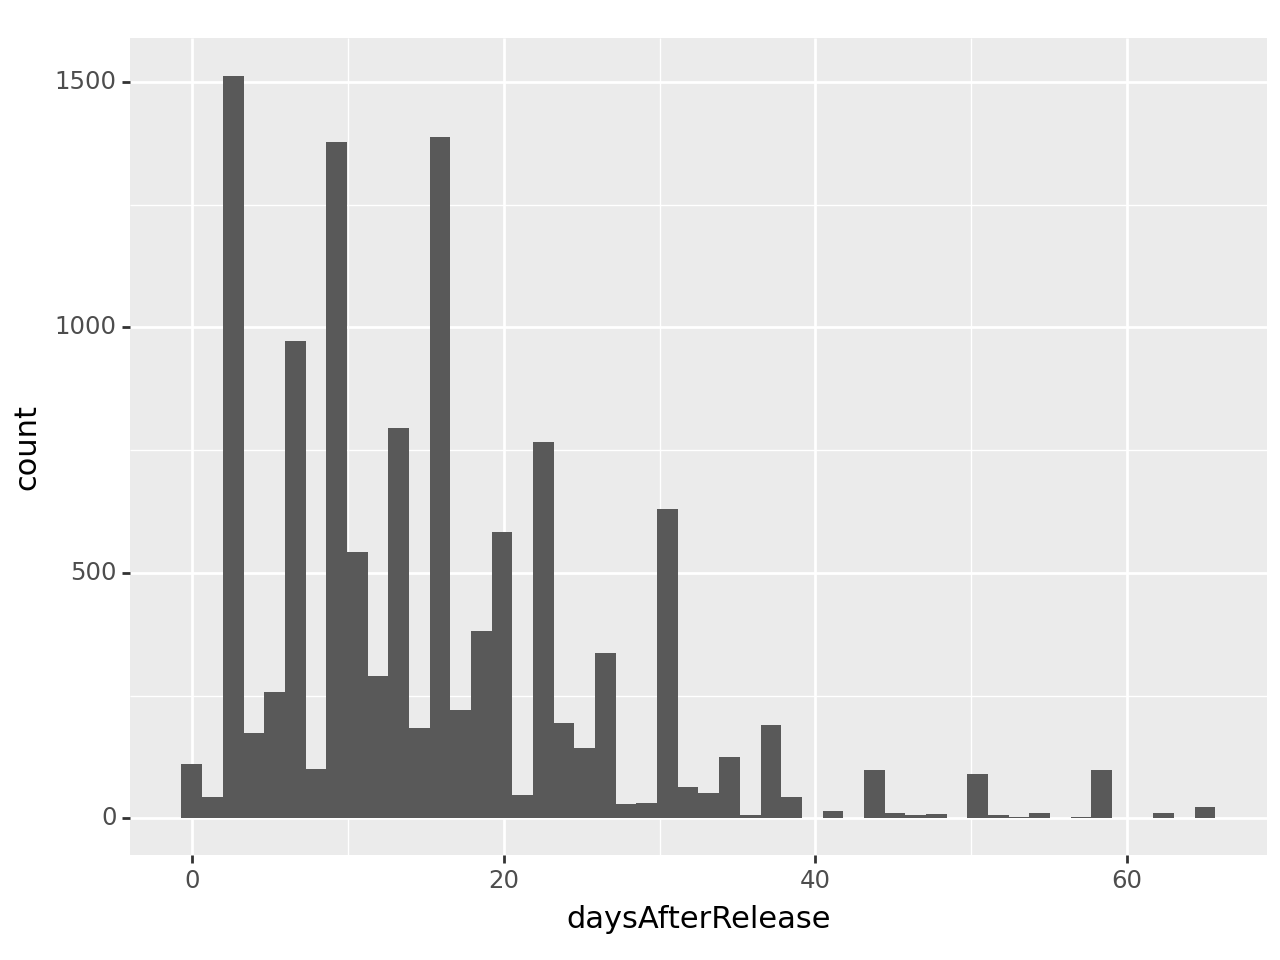

<Figure Size: (640 x 480)>

In [10]:
(ggplot(df, aes(x = "daysAfterRelease")) +
   geom_histogram())

Notice the warning about bin sizes. You can customize the number or width of the bins with `bins =` or `binwidth =`:

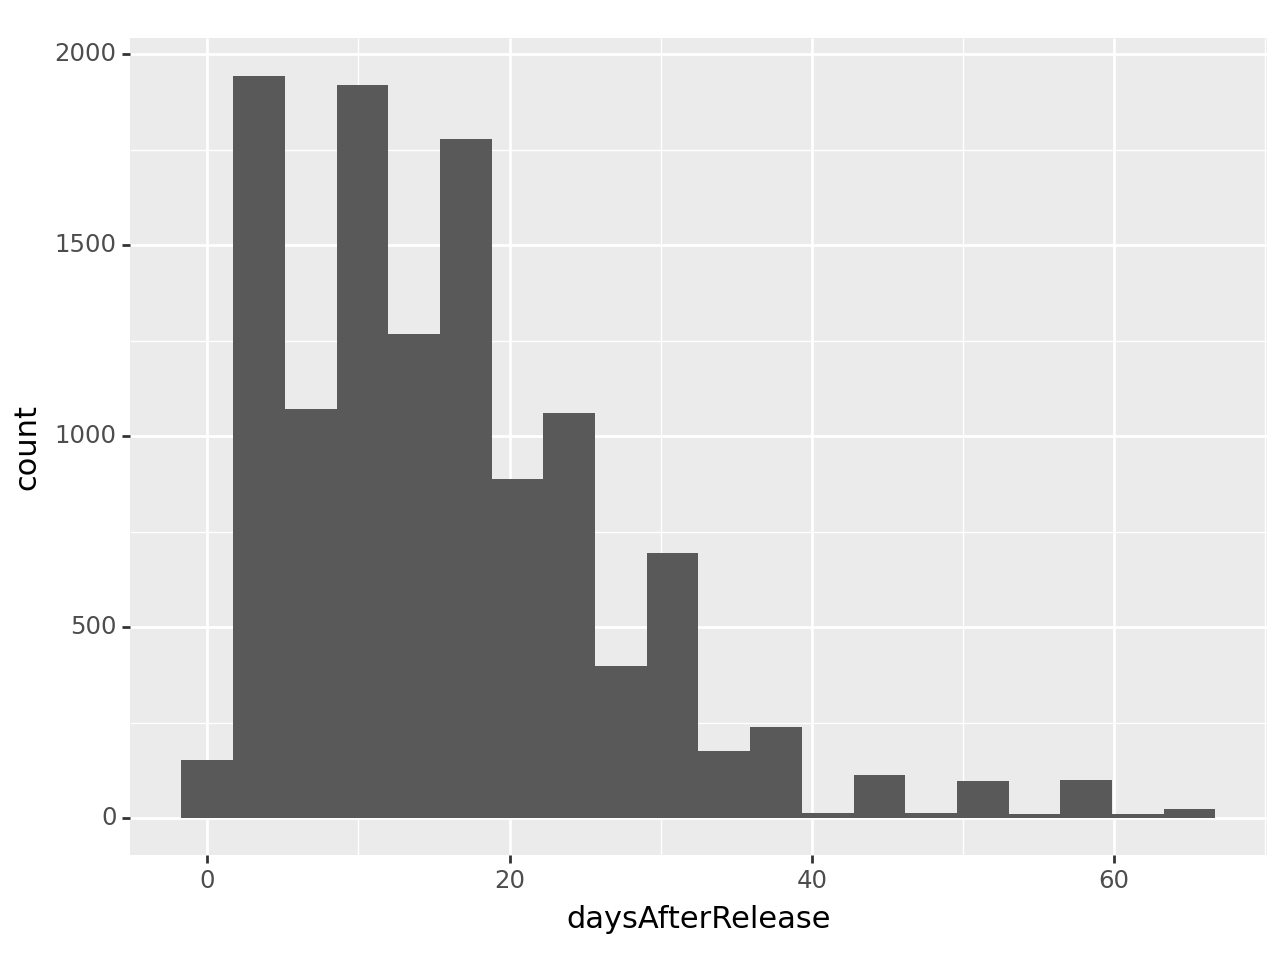

<Figure Size: (640 x 480)>

In [11]:
(ggplot(df, aes(x = "daysAfterRelease")) +
   geom_histogram(bins = 20))

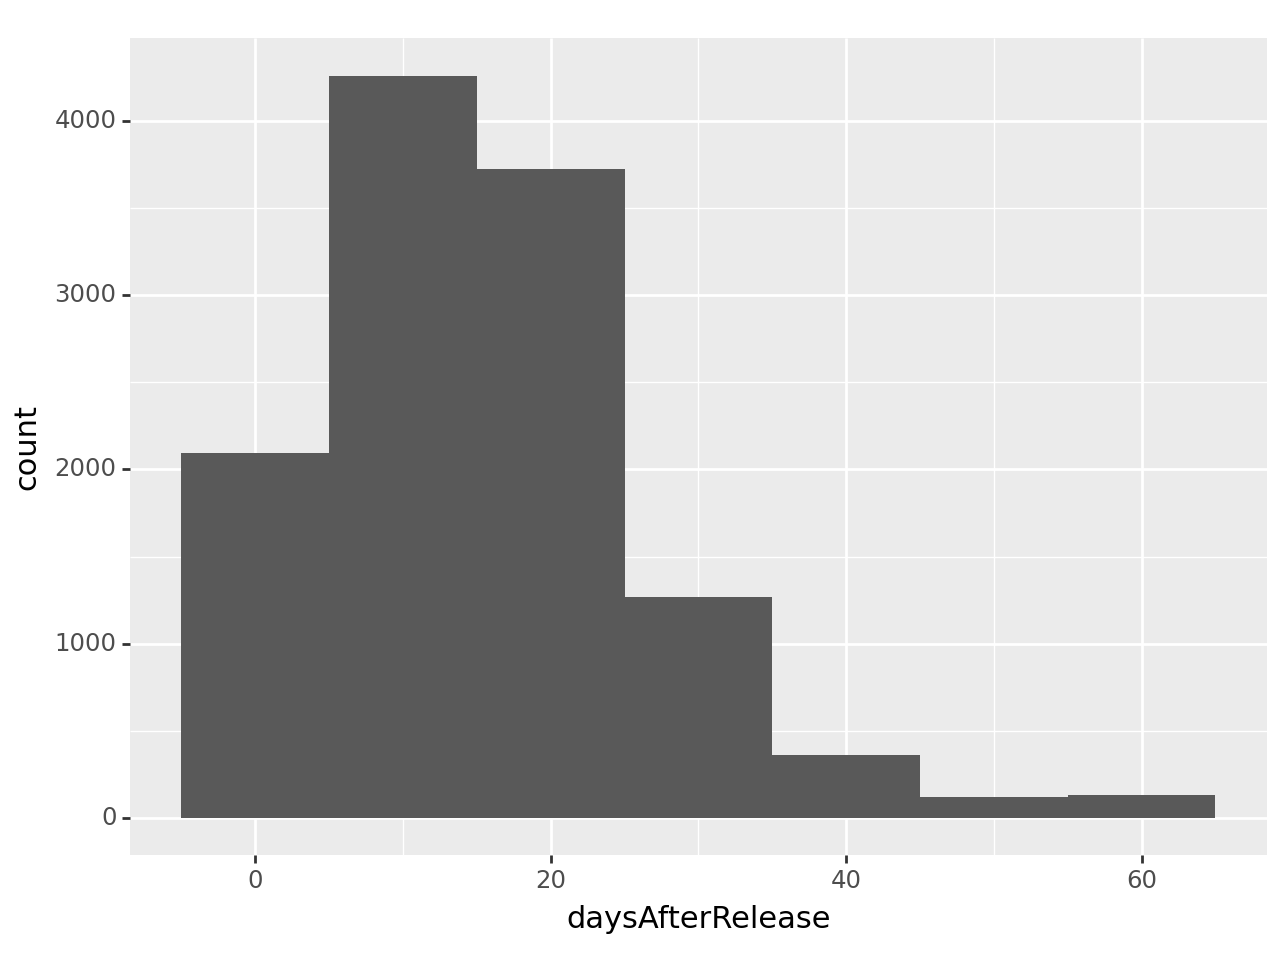

<Figure Size: (640 x 480)>

In [12]:
(ggplot(df, aes(x = "daysAfterRelease")) +
   geom_histogram(binwidth = 10))

If you'd like to show proportions on the y-axis instead of counts, you can use `geom_density()`:

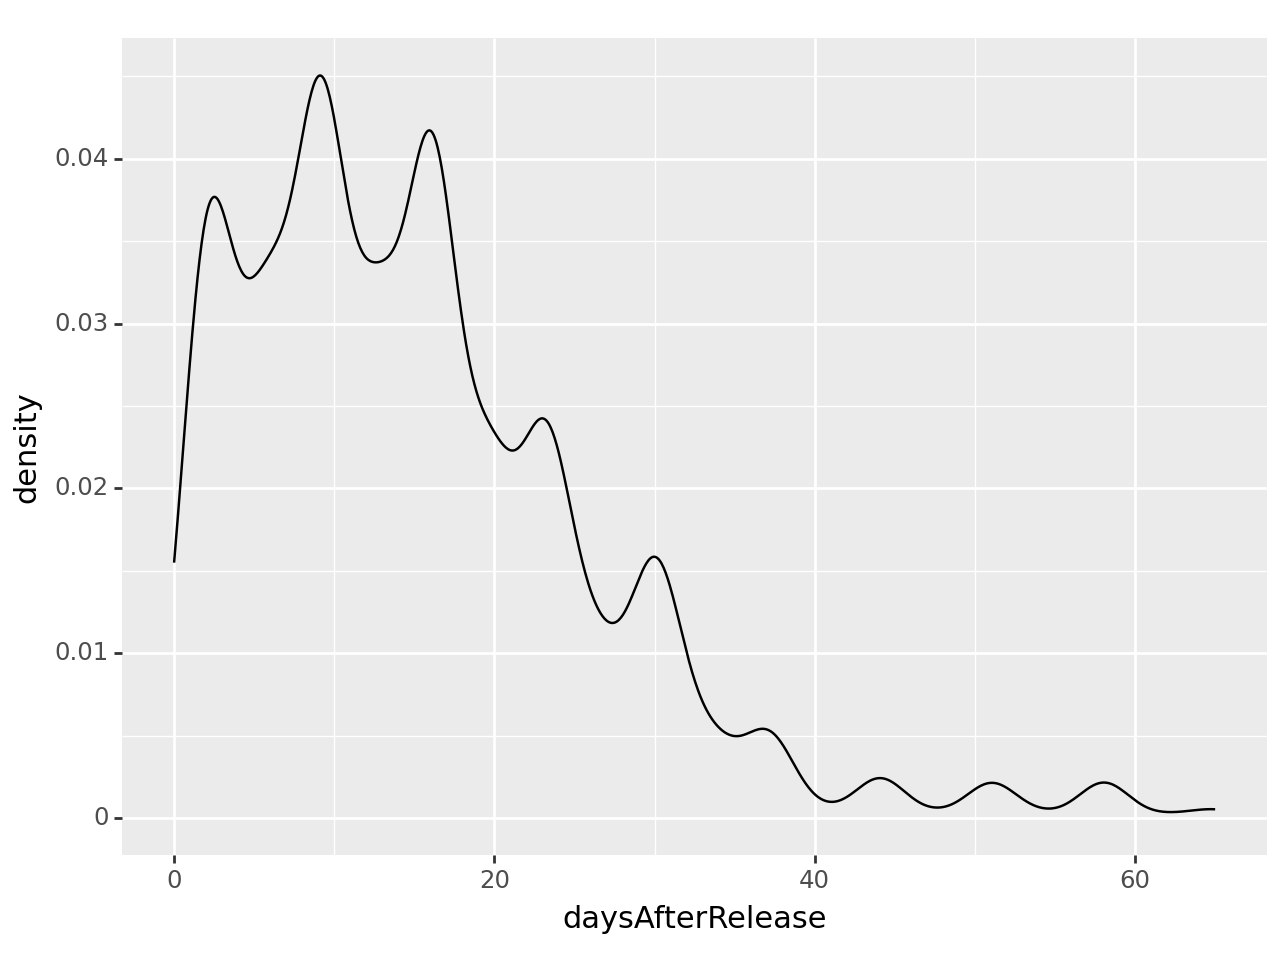

<Figure Size: (640 x 480)>

In [13]:
((ggplot(df, aes(x = "daysAfterRelease")) +
   geom_density()))

Density histograms are good for showing the distribution of a numeric variable broken out by a categorical variable. For this, you'd include the categorical variable in your aesthetic layer as `color=`:

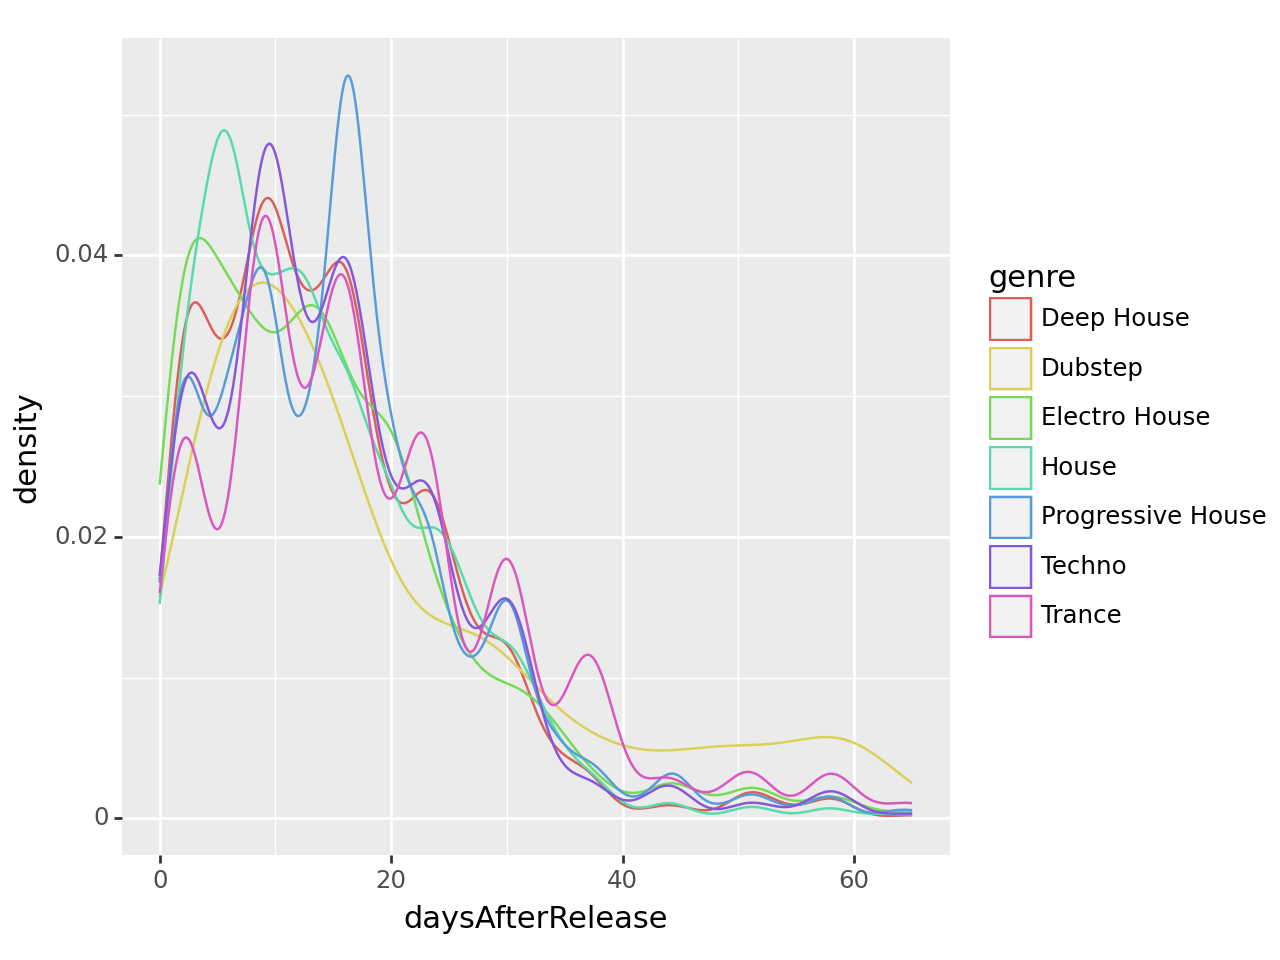

<Figure Size: (640 x 480)>

In [14]:
(ggplot(df, aes(x = "daysAfterRelease", color = "genre")) +
   geom_density())

Now you try...create a histogram for the `artistSongs` variable, using a bin width of 250:

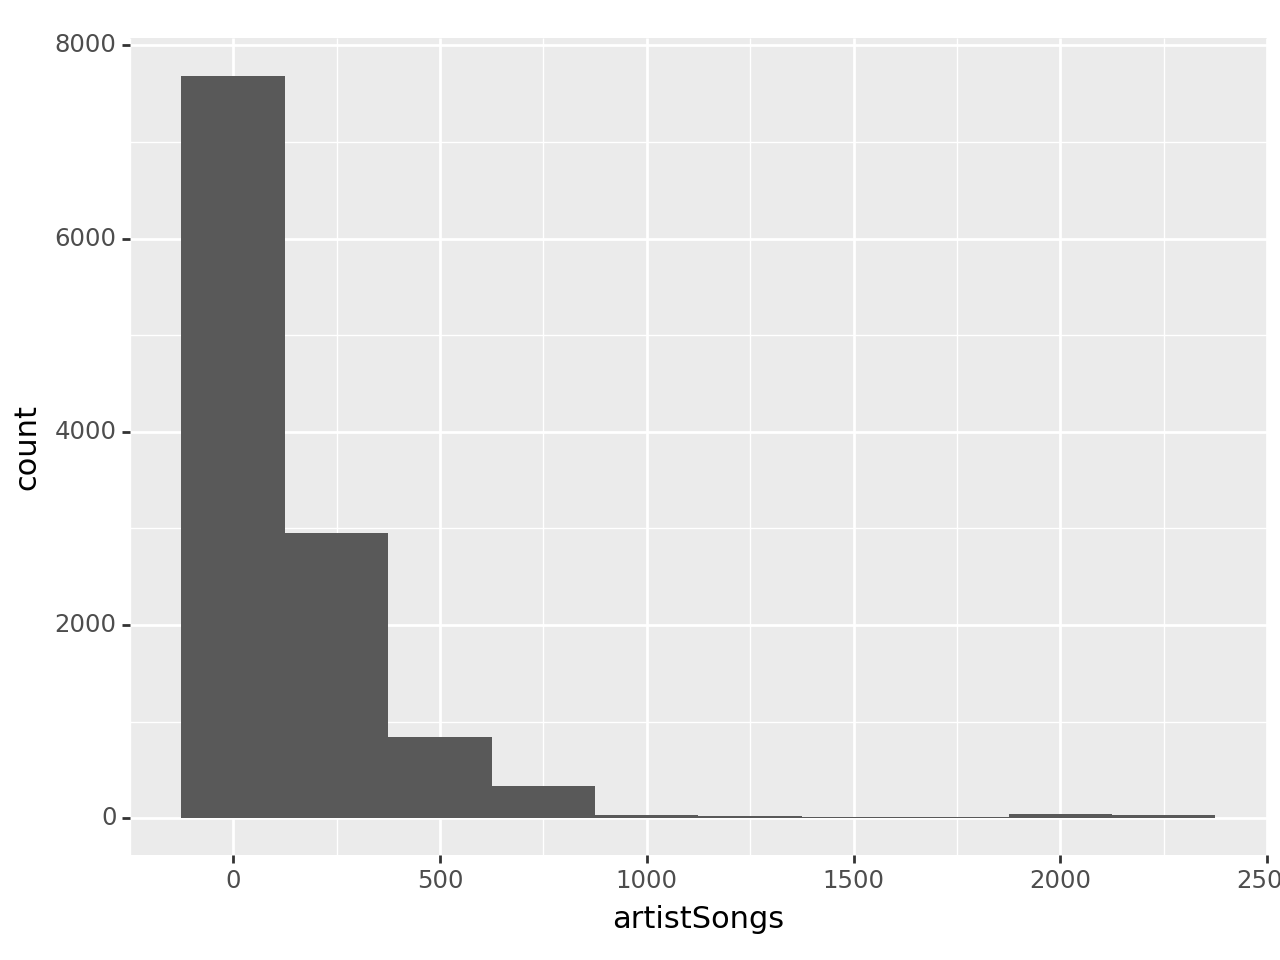

<Figure Size: (640 x 480)>

In [15]:
(ggplot(df, aes(x = "artistSongs")) +
   geom_histogram(binwidth = 250))

#### Boxplots

Another good visualization for numeric data is the boxplot. Unlike a histogram, where the variable goes on the x-axis, you need to put the variable on the y-axis for a boxplot:

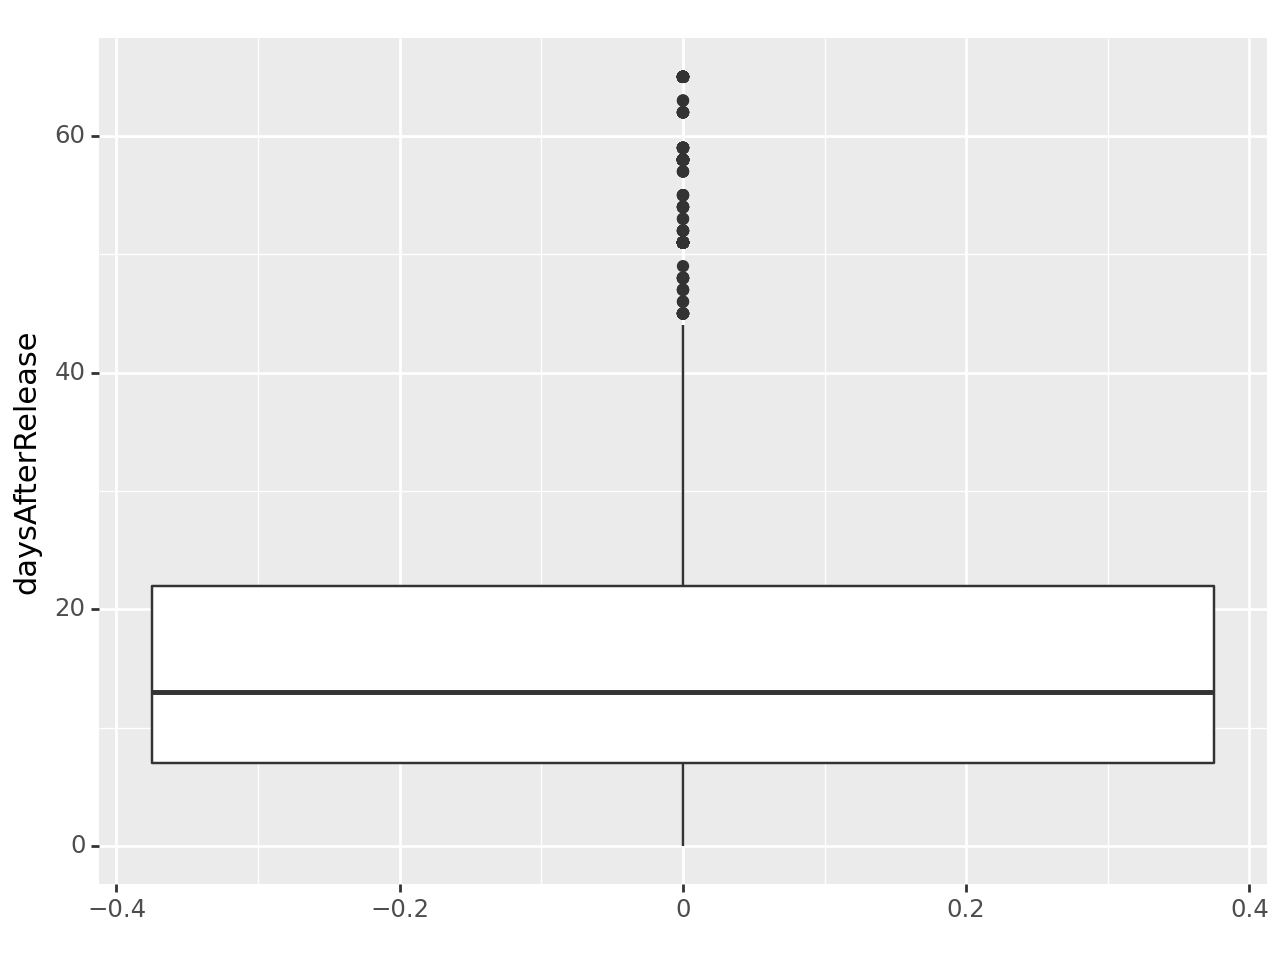

<Figure Size: (640 x 480)>

In [16]:
(ggplot(df, aes(y = "daysAfterRelease")) +
   geom_boxplot())

Although the variable needs to go on the y-axis, you can use `+ coord_flip()` to rotate the axis 90 degrees:

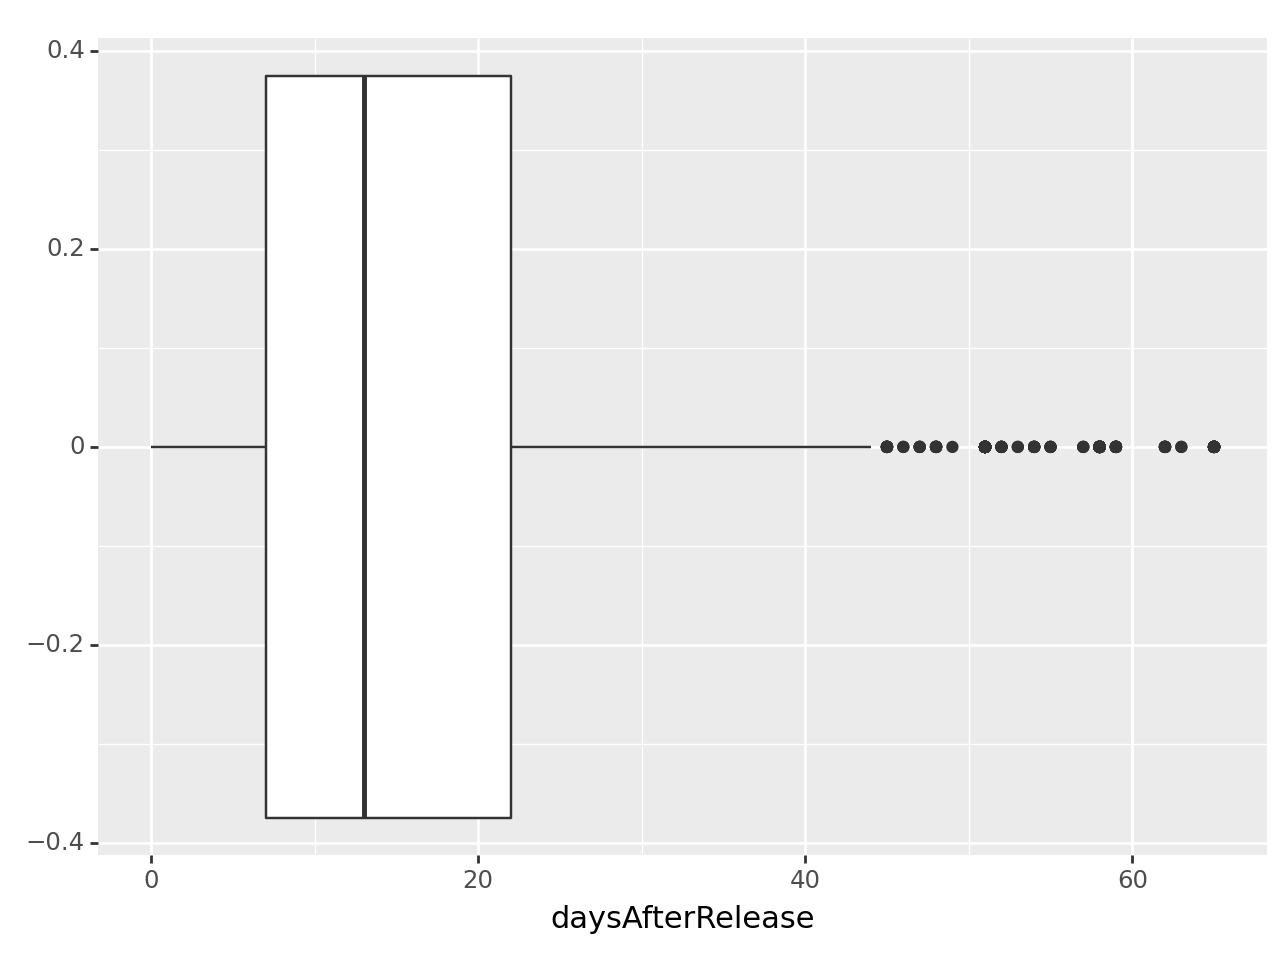

<Figure Size: (640 x 480)>

In [17]:
(ggplot(df, aes(y = "daysAfterRelease")) +
   geom_boxplot() +
   coord_flip())

I like this orientation because it makes it easier to compare the histogram vs. boxplot:

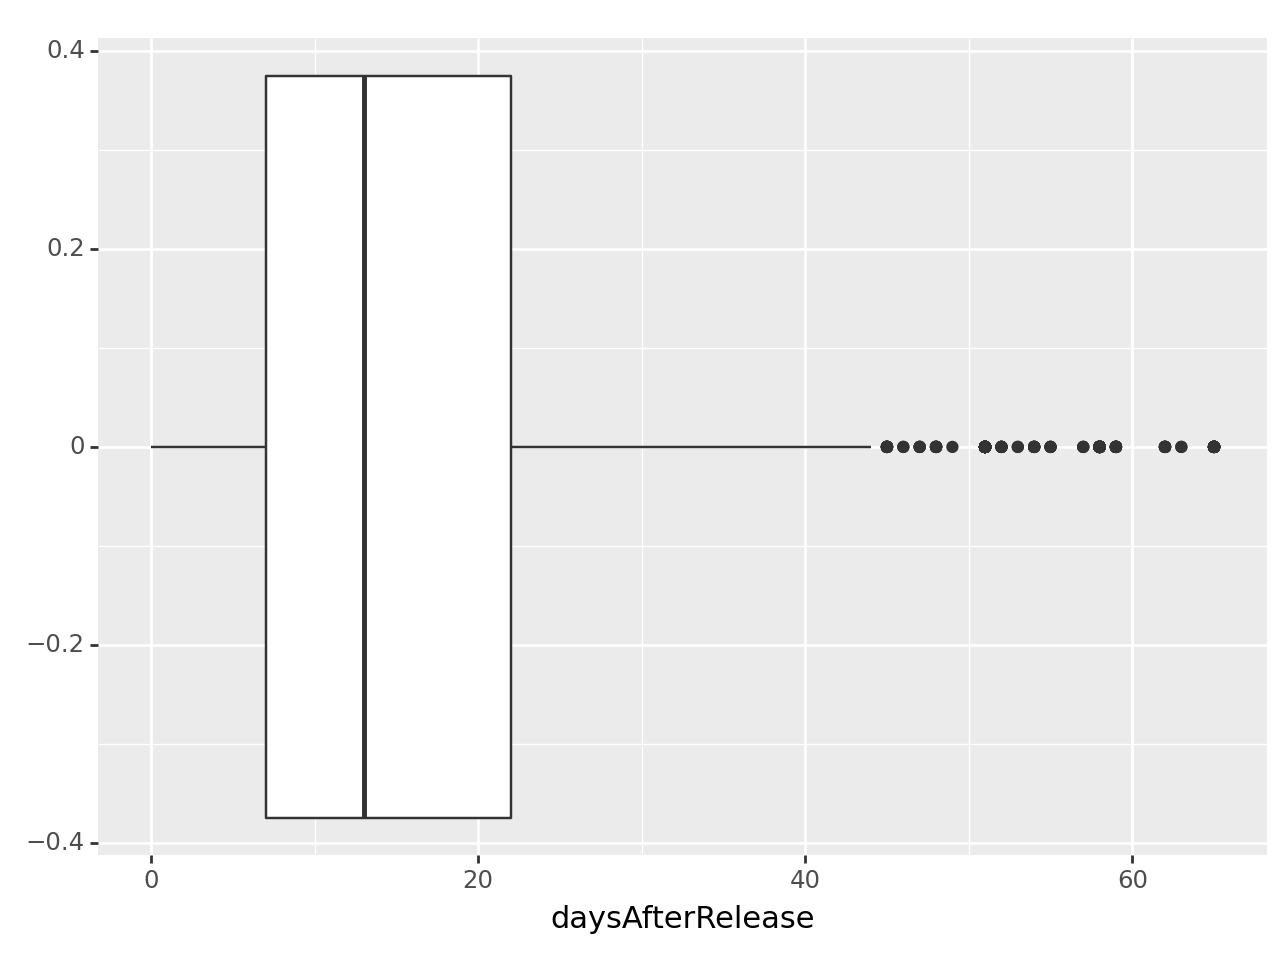

<Figure Size: (640 x 480)>

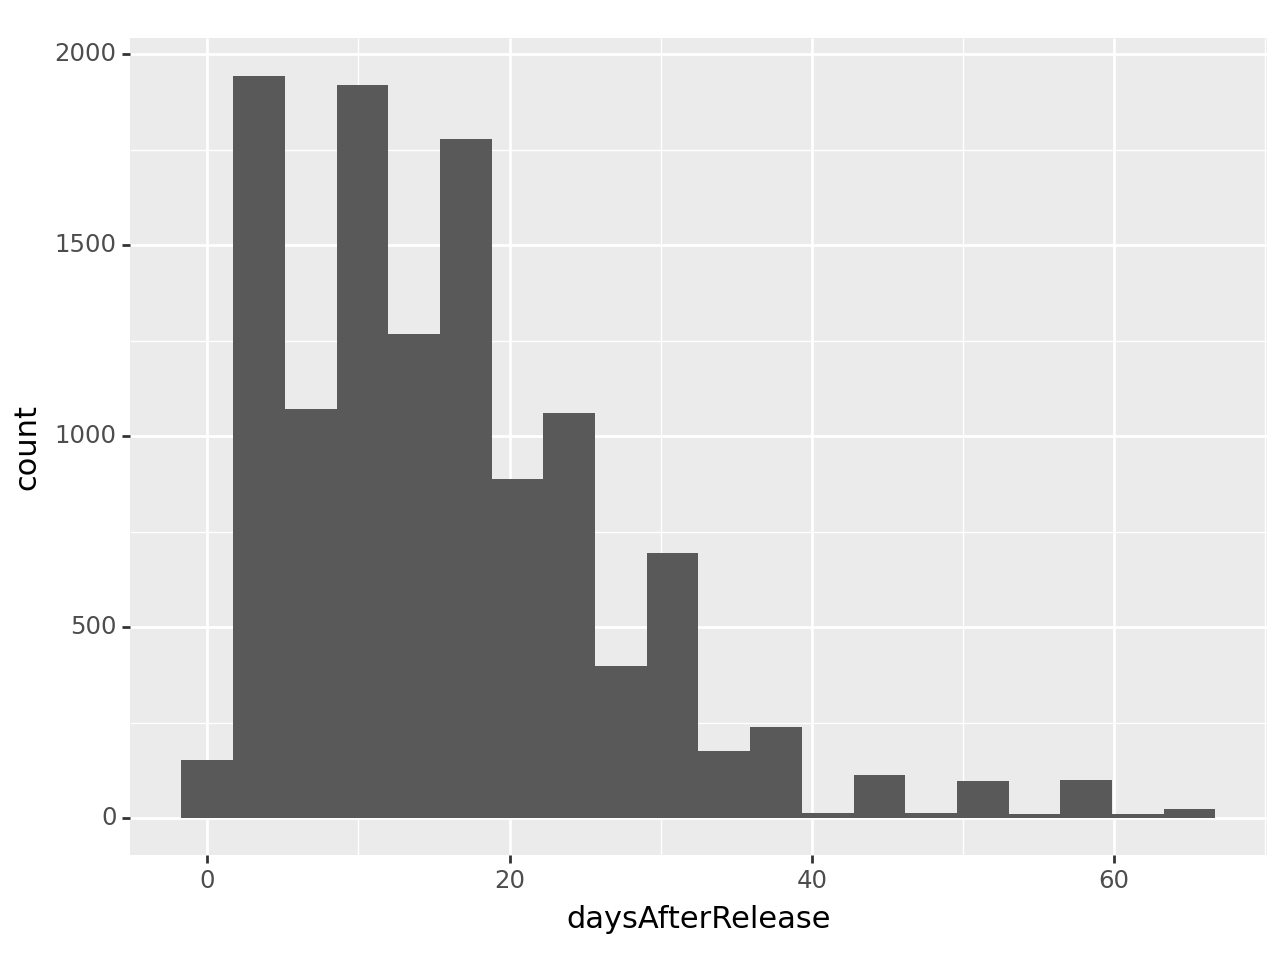

<Figure Size: (640 x 480)>

In [18]:
(ggplot(df, aes(y = "daysAfterRelease")) +
   geom_boxplot() +
   coord_flip())
(ggplot(df, aes(x = "daysAfterRelease")) +
   geom_histogram(bins = 20))

The histogram clearly shows where the modes are, while the boxplot shows the outliers.

Just as with density histograms, you can also break a boxplot out by categories by using `x=`:

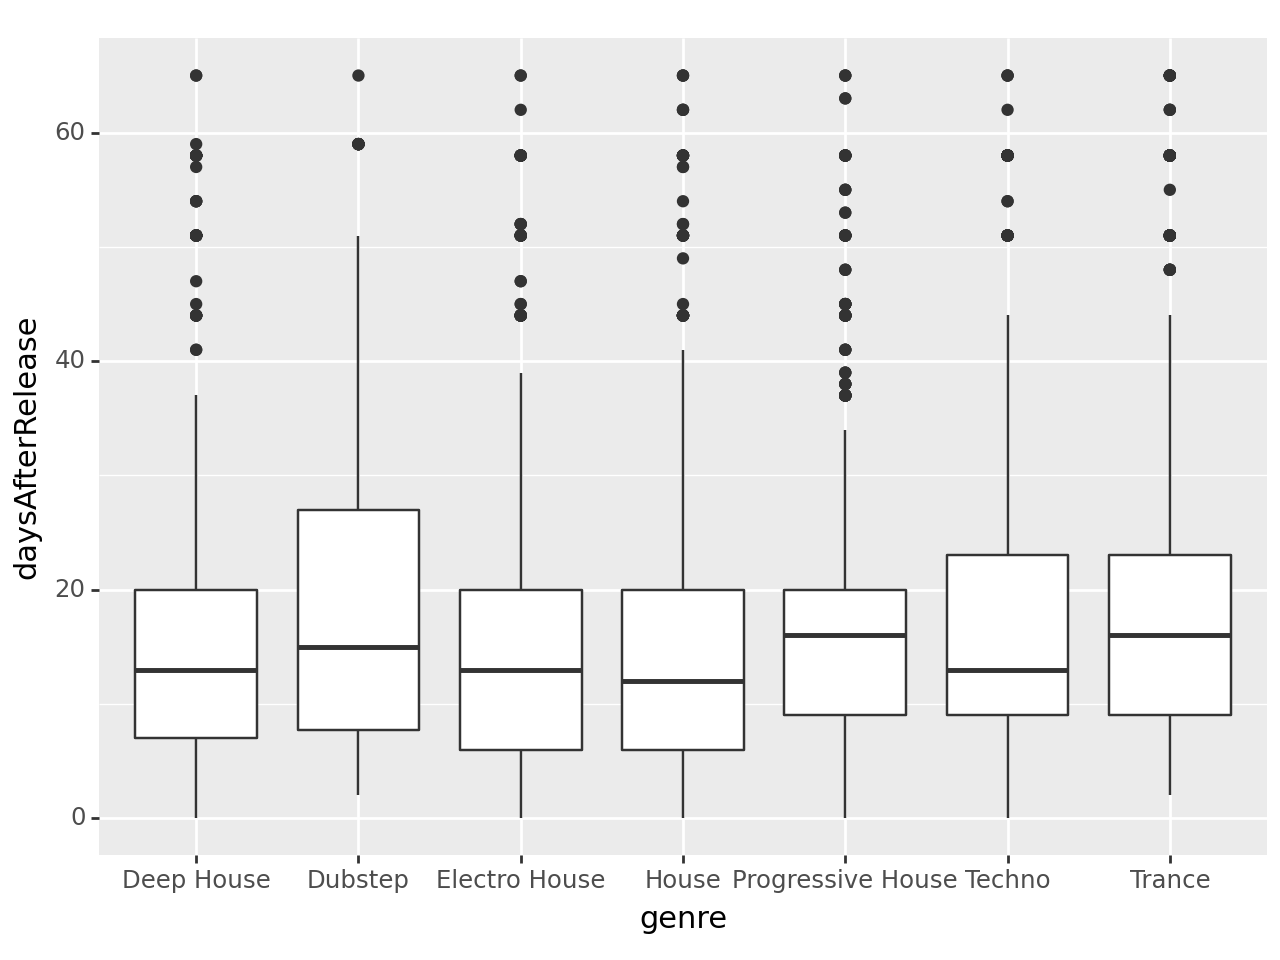

<Figure Size: (640 x 480)>

In [19]:
(ggplot(df, aes(y = "daysAfterRelease", x = "genre")) +
   geom_boxplot())

Or with the axes flipped...

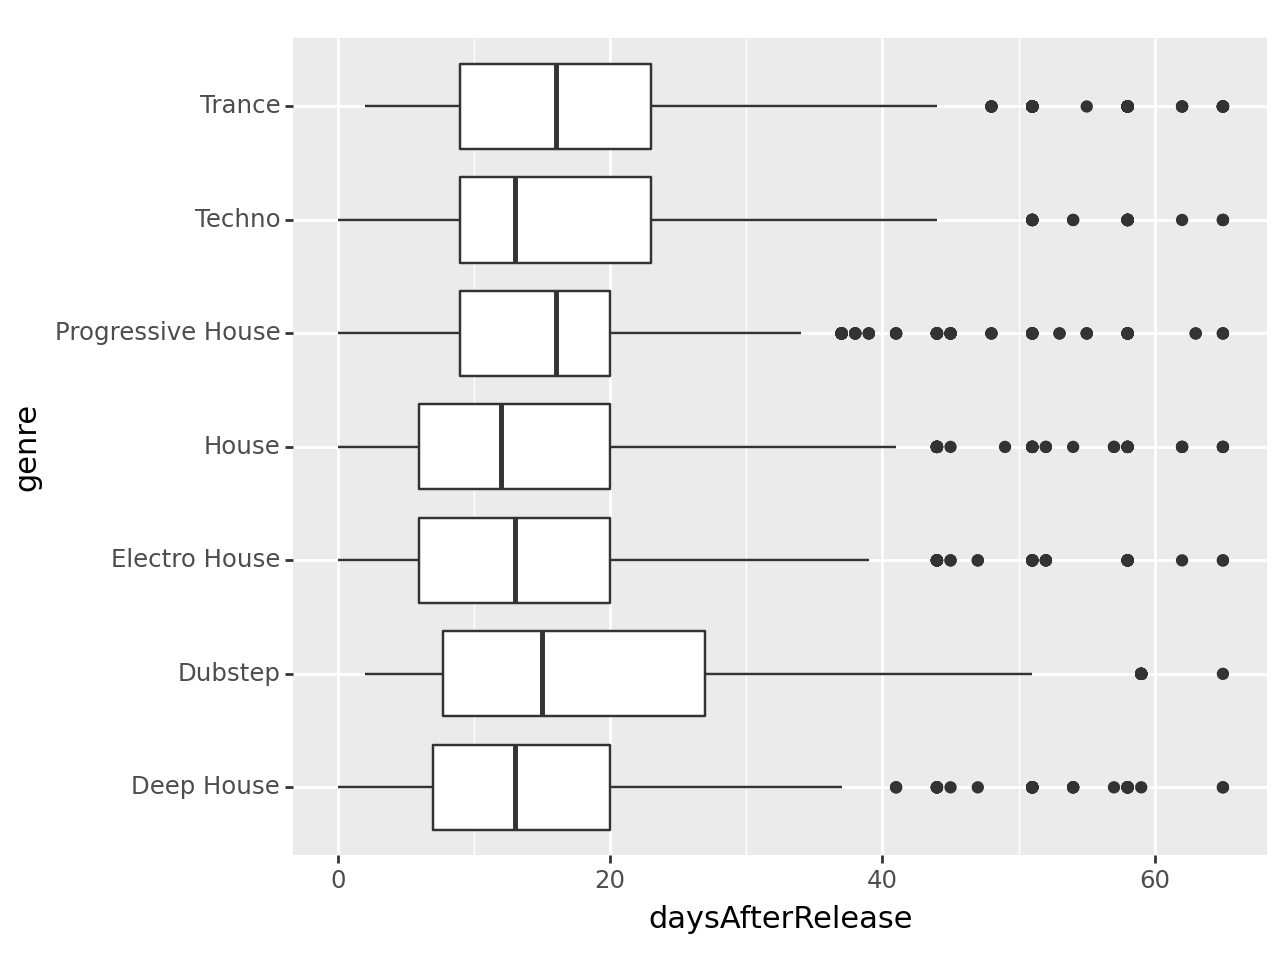

<Figure Size: (640 x 480)>

In [20]:
(ggplot(df, aes(y = "daysAfterRelease", x = "genre")) +
   geom_boxplot() +
   coord_flip())

Now you try...create a boxplot for the "artistSongs" variable:

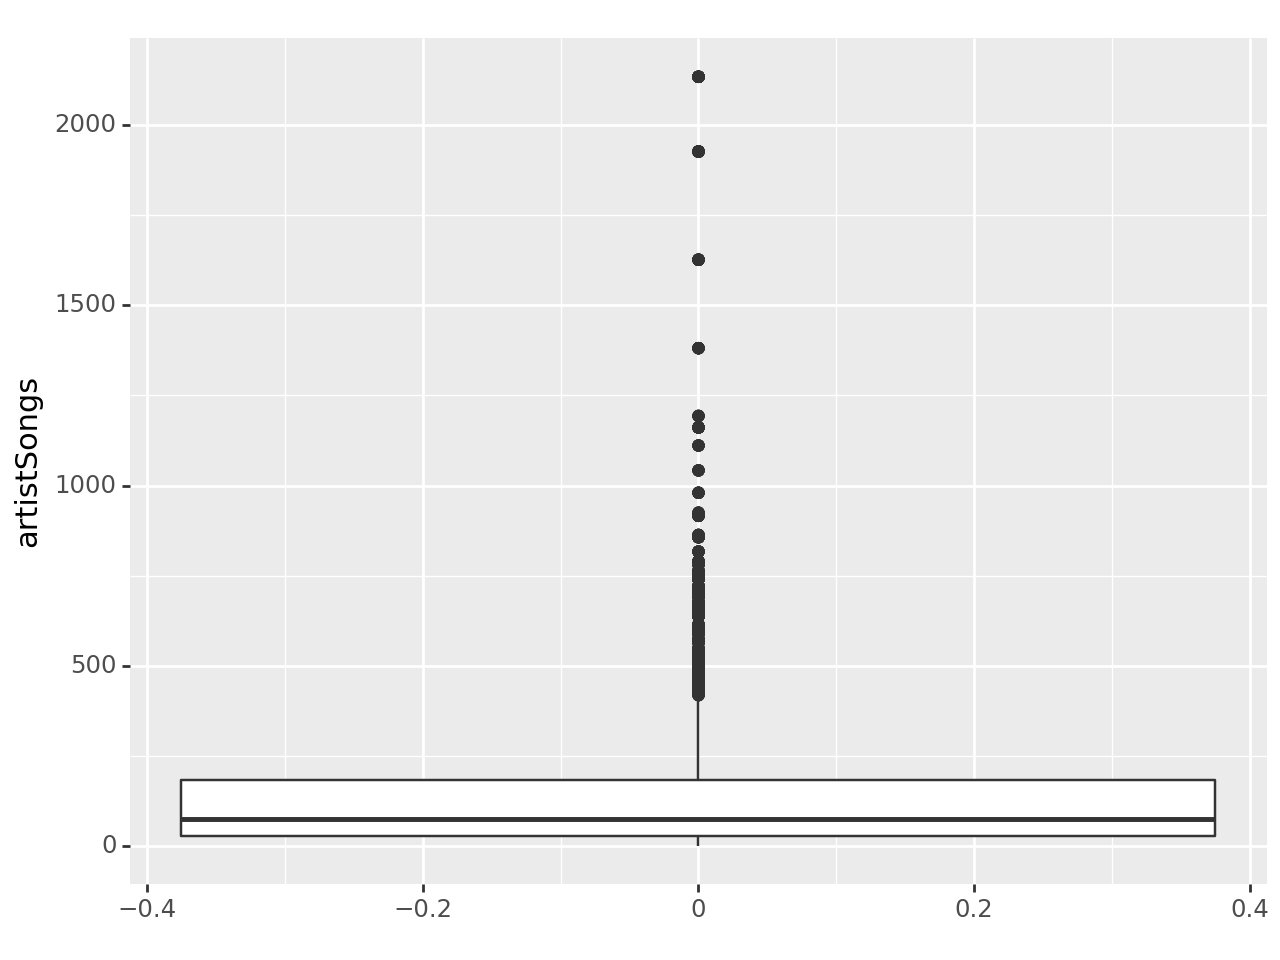

<Figure Size: (640 x 480)>

In [21]:
(ggplot(df, aes(y = "artistSongs")) + 
   geom_boxplot())

Now split the "artistSongs" variable by "genre" and display your boxplots horizontally:

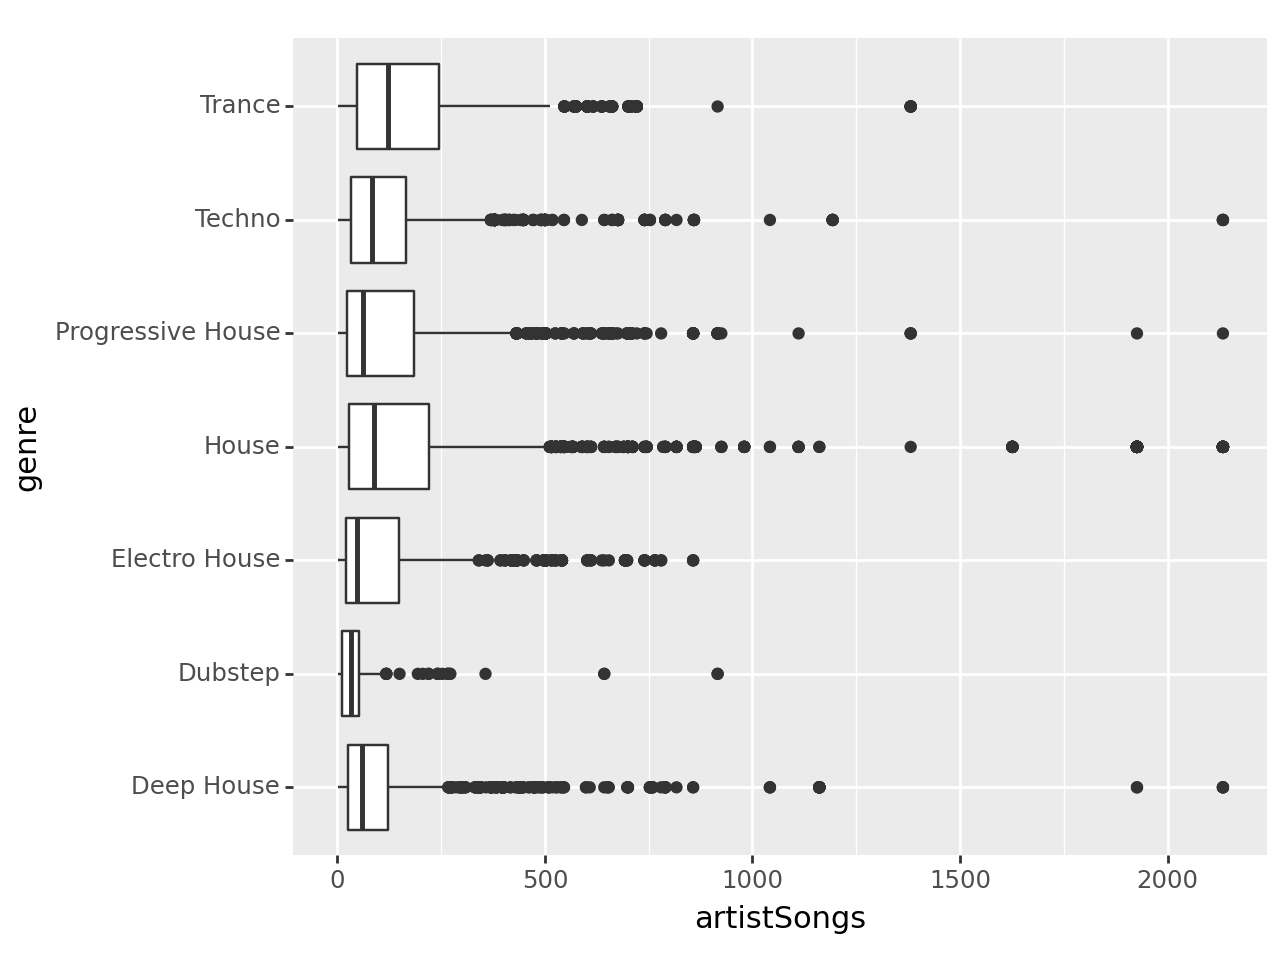

<Figure Size: (640 x 480)>

In [22]:
(ggplot(df, aes(y = "artistSongs", x = "genre")) +
   geom_boxplot() +
   coord_flip())

#### Scatter Plots

To view the relationship between 2 numeric variables, a scatter plot is best. As we've already seen, you use `geom_point()` to draw a scatter plot. For example:

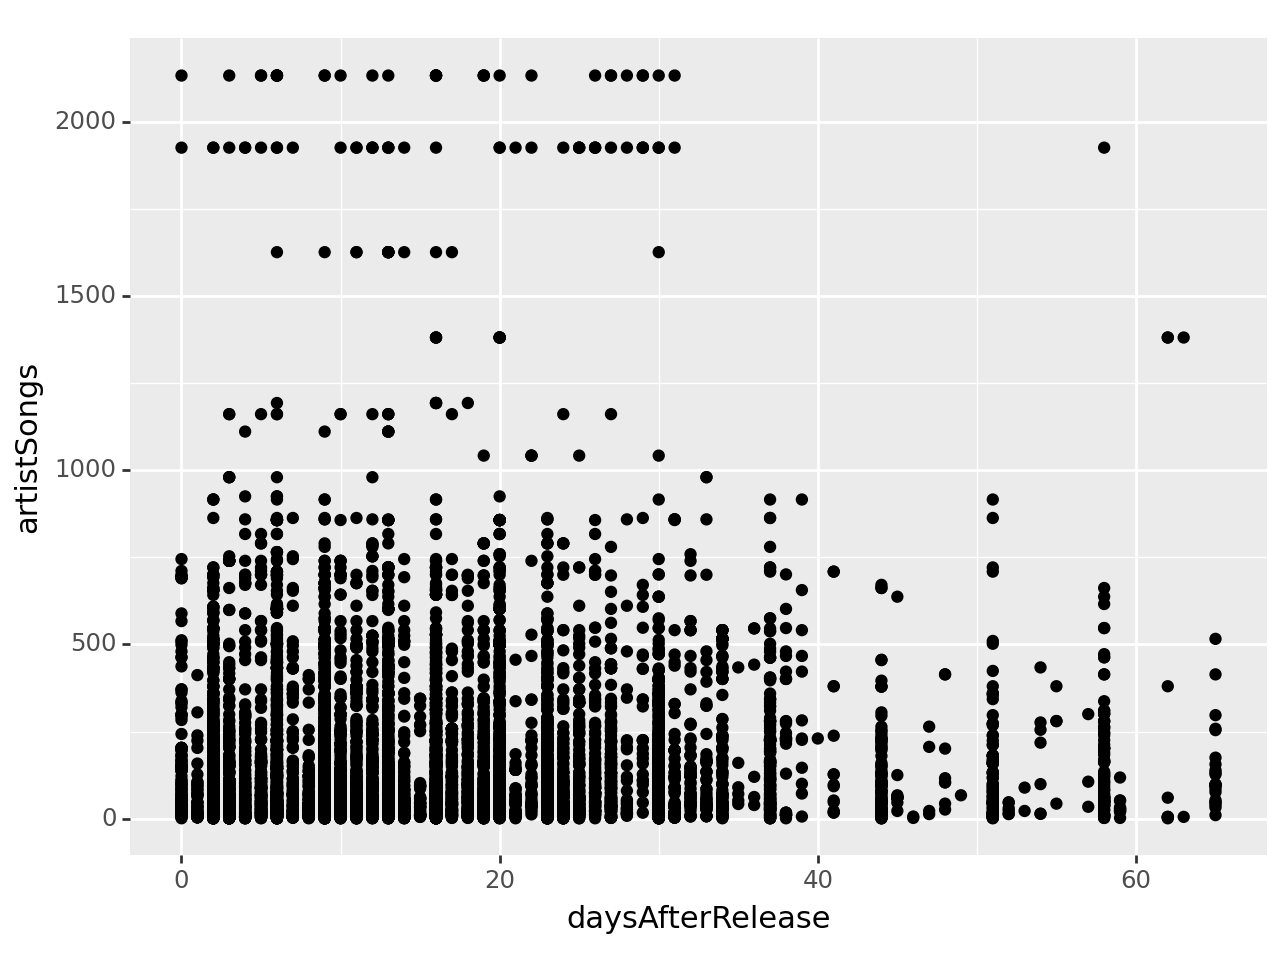

<Figure Size: (640 x 480)>

In [23]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs")) +
   geom_point())

Given the large amount of data, it's hard to see how many points are overlapping. To adjust this, you can include `alpha=` in your `geom_point()` layer...alpha ranges from 0 to 1, which 0 being transparent and 1 being solid.

Here, I've used an alpha of 0.3 to show some transparency:

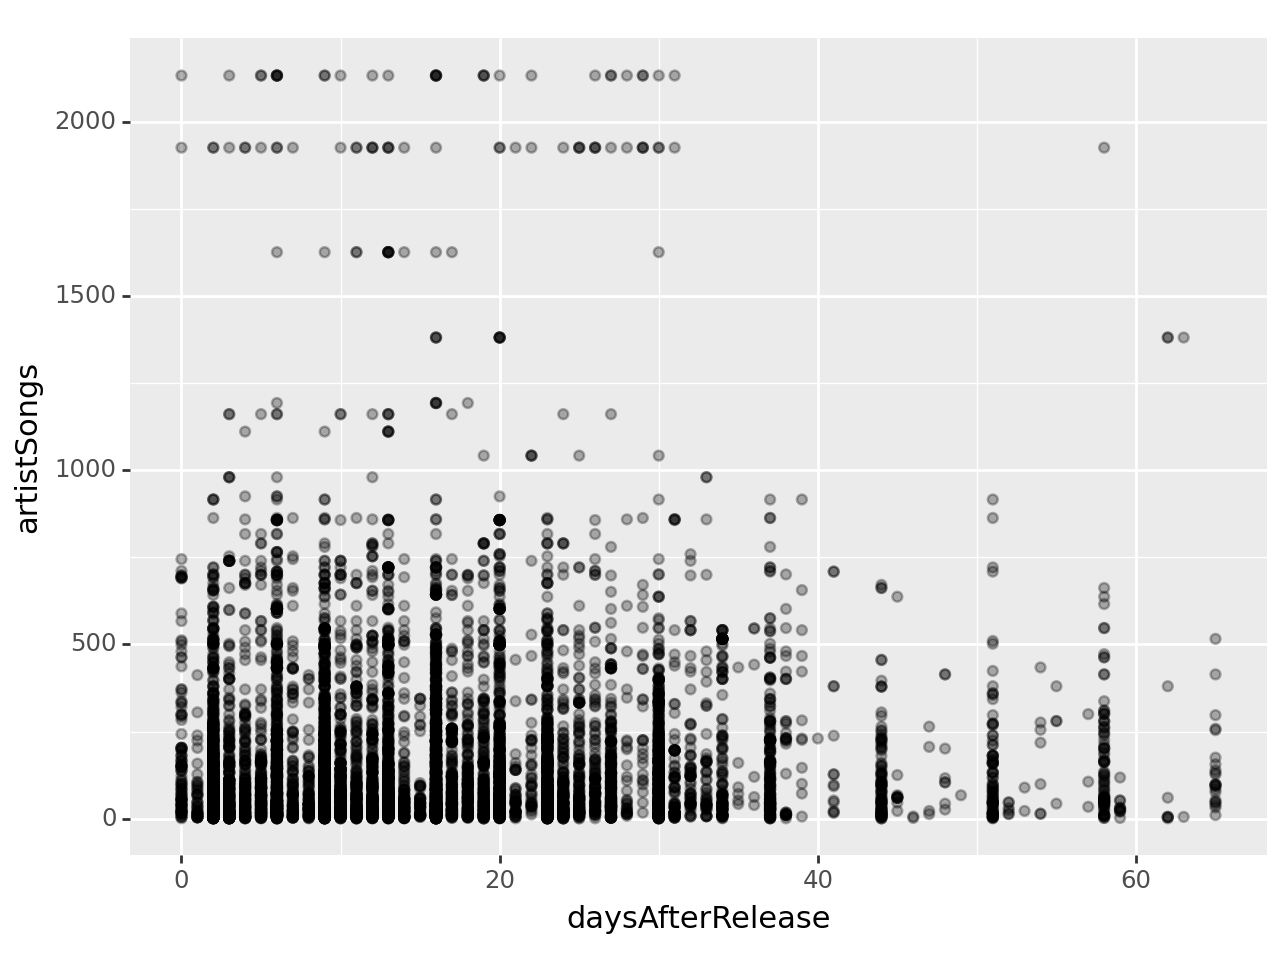

<Figure Size: (640 x 480)>

In [24]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs")) +
   geom_point(alpha = 0.3))

You can add other variables using `color`, `size`, or `shape`. Here, I've mapped the `genre` variable to the `color` attribute:

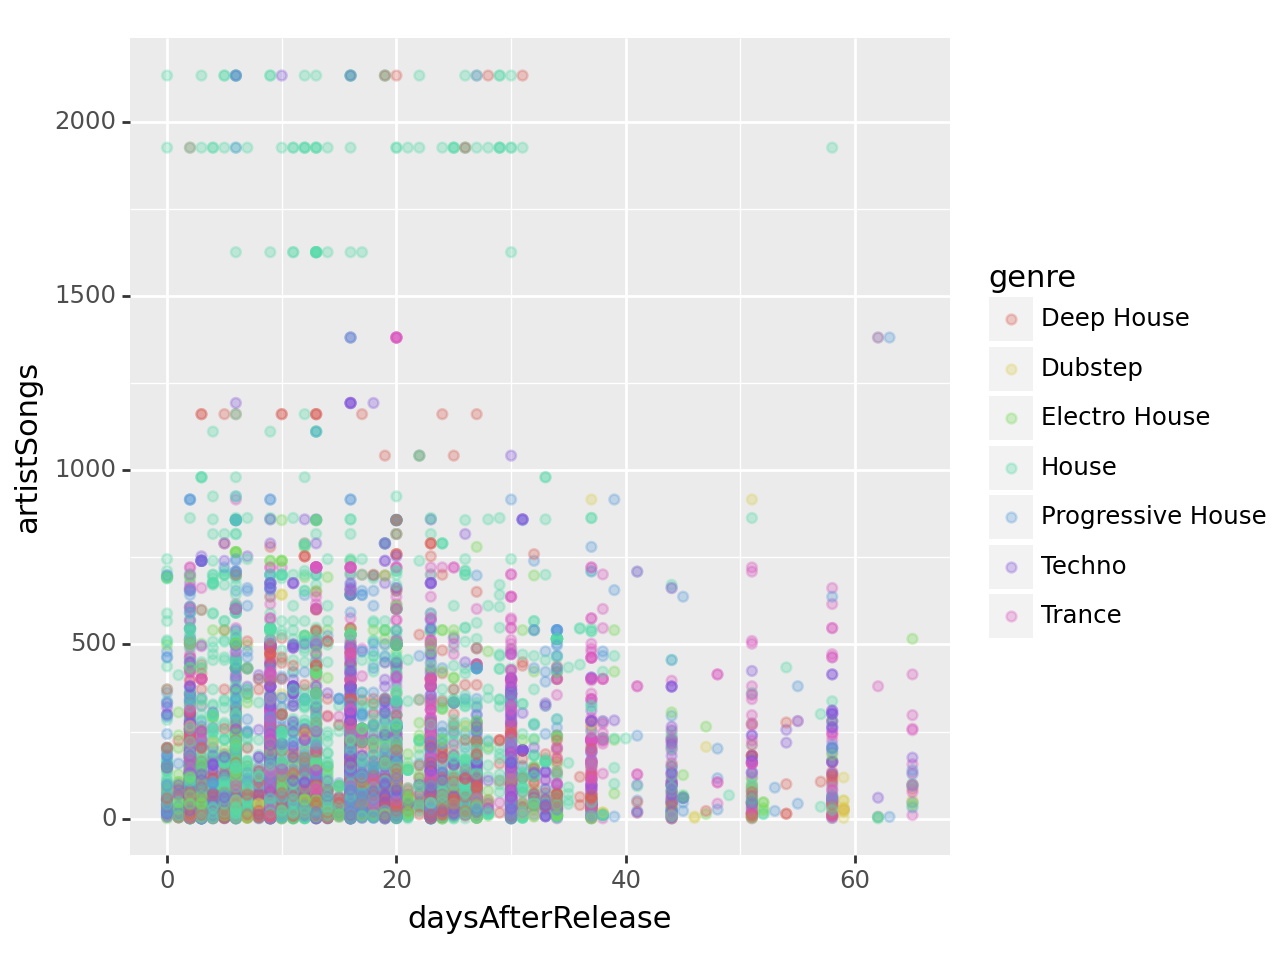

<Figure Size: (640 x 480)>

In [25]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs", color = "genre")) +
   geom_point(alpha = 0.3))

Copy/paste the code for the above graph and see if you can figure out how to add "enteredCharts" as a `size` attribute:

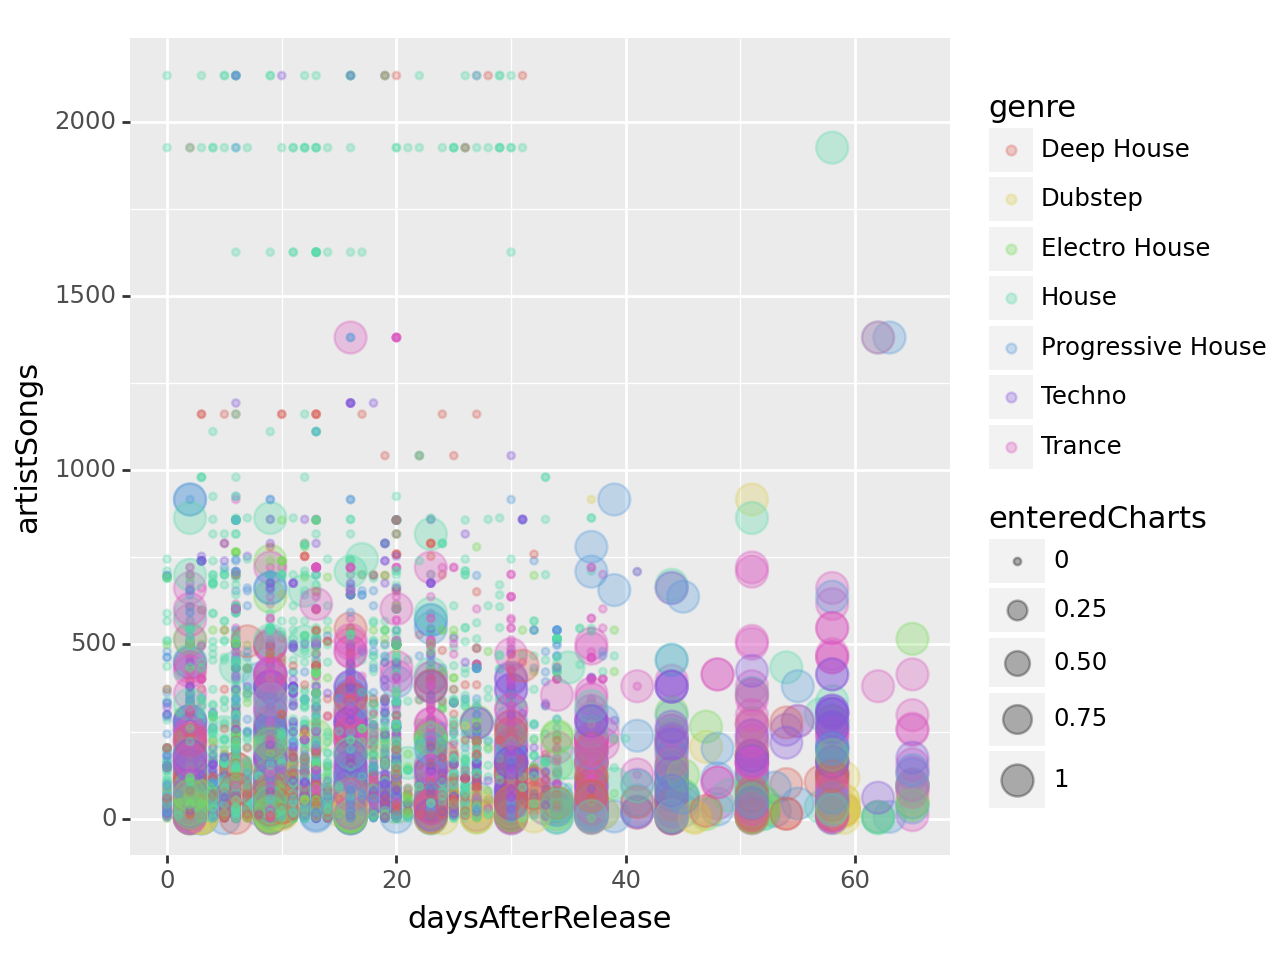

<Figure Size: (640 x 480)>

In [26]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs", color = "genre",
               size = "enteredCharts")) +
   geom_point(alpha = 0.3))

The "enteredCharts" variable only has 2 values: 0 for "did not enter the charts" and 1 for "entered the charts". If this is the case, why did the `size` attribute display with values between 0 and 1?

When you have a numerically coded variable that you want graphed as categorical, you can use `factor()`...e.g., `factor(enteredCharts)`. Revise your code to re-draw the graph so that it only shows sizes for 0 and 1:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/scales/scale_size.py:49: PlotnineWarning: Using size for a discrete variable is not advised.


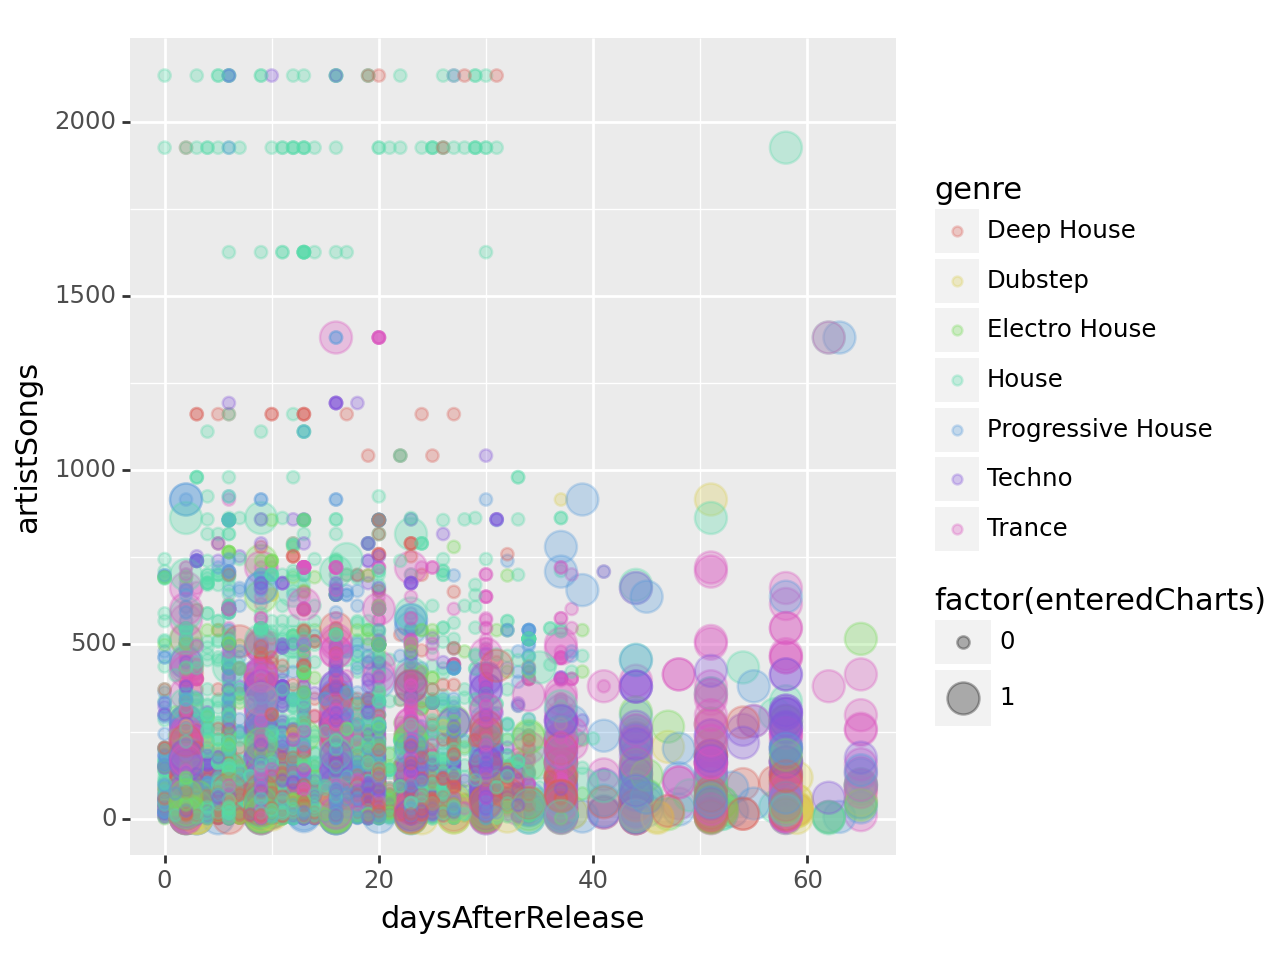

<Figure Size: (640 x 480)>

In [27]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs", color = "genre",
               size = "factor(enteredCharts)")) +
   geom_point(alpha = 0.3))

Notice the warning message...`size` is typically reserved for numeric variables. Update your graph to map `factor(enteredCharts)` to `shape` instead of `size`:

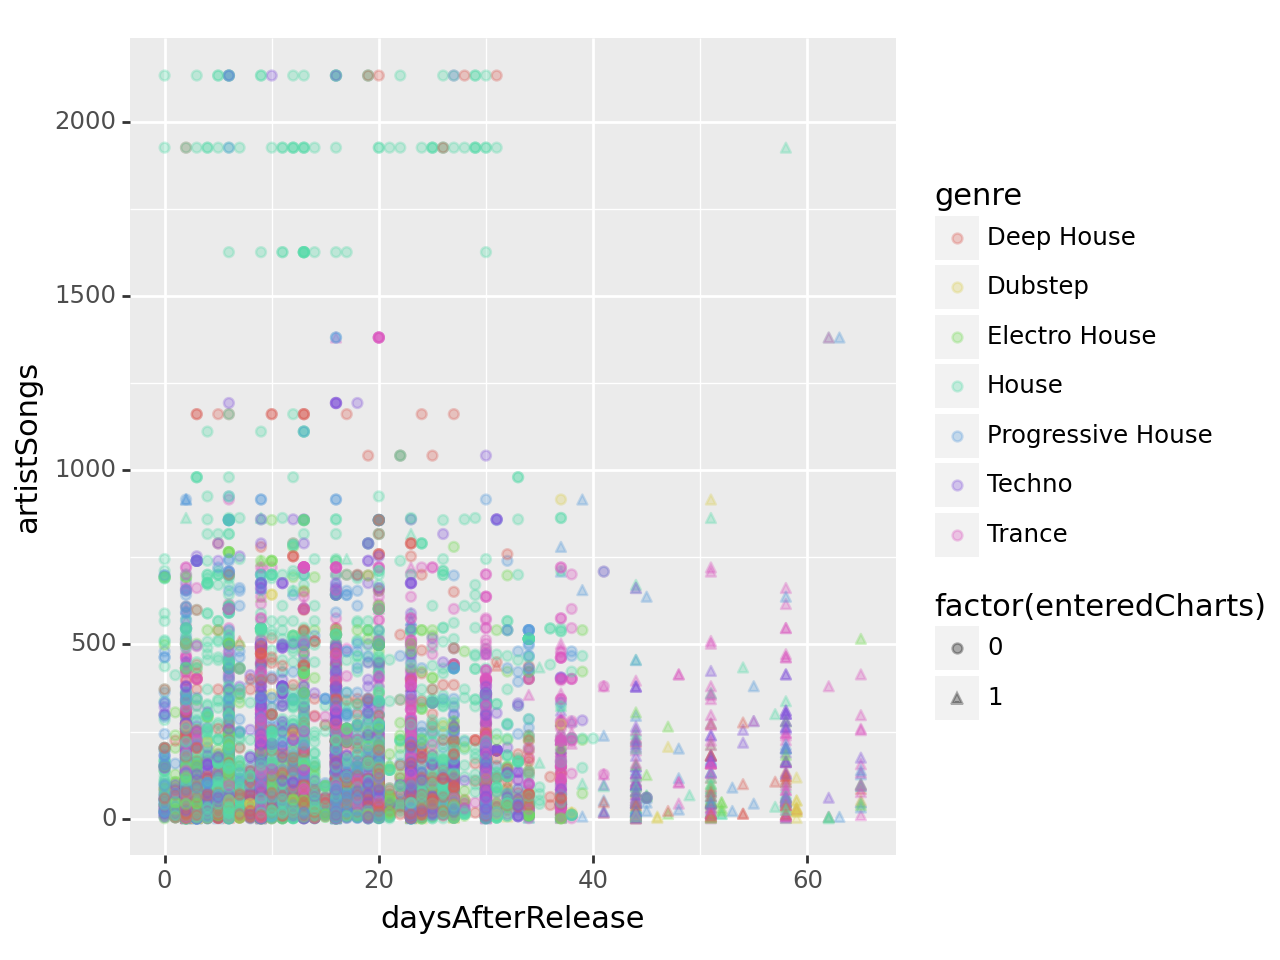

<Figure Size: (640 x 480)>

In [28]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs", color = "genre",
               shape = "factor(enteredCharts)")) +
   geom_point(alpha = 0.3))

Based on the visualization principles we discussed, this is definitely an example of "design variation not showing data variation". There's too much going on in this graph to be able to make any sense of the data. The point here is that, just because you *can* graph 5 variables to a scatter plot doesn't mean you should.

Let's re-draw the scatter plot removing "genre" and using the `color` attribute for whether or not a song entered the charts:

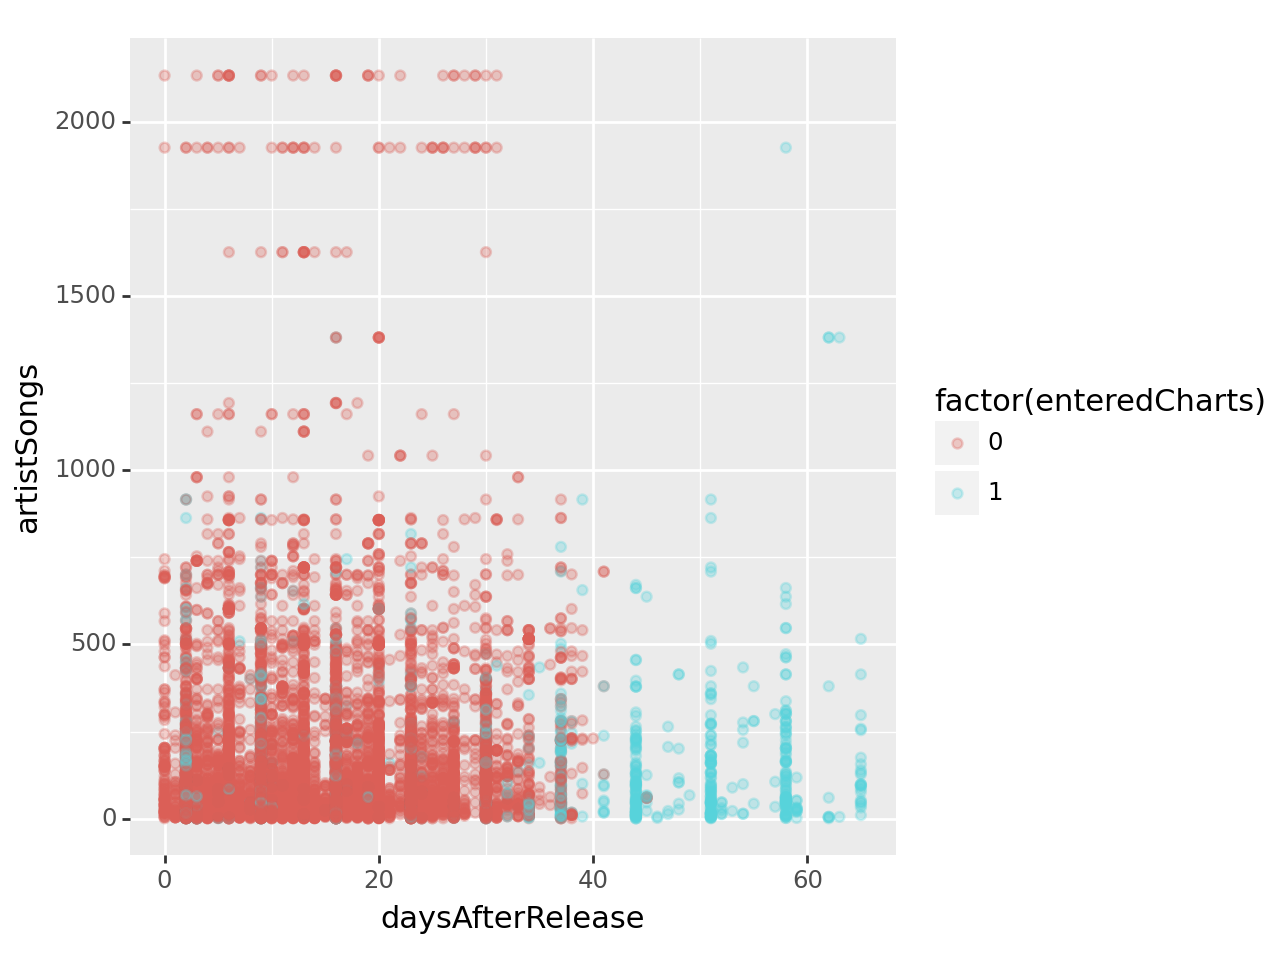

<Figure Size: (640 x 480)>

In [29]:
(ggplot(df, aes(x = "daysAfterRelease", y = "artistSongs", 
                color = "factor(enteredCharts)")) +
   geom_point(alpha = 0.3))

Now, what can you say about the data based on this graph?

#### Smoothed lines

It's often useful to include regression lines on a scatter plot. You can use `geom_smooth()` to do this. For a linear regression line, you would include `method = "lm"` as follows:

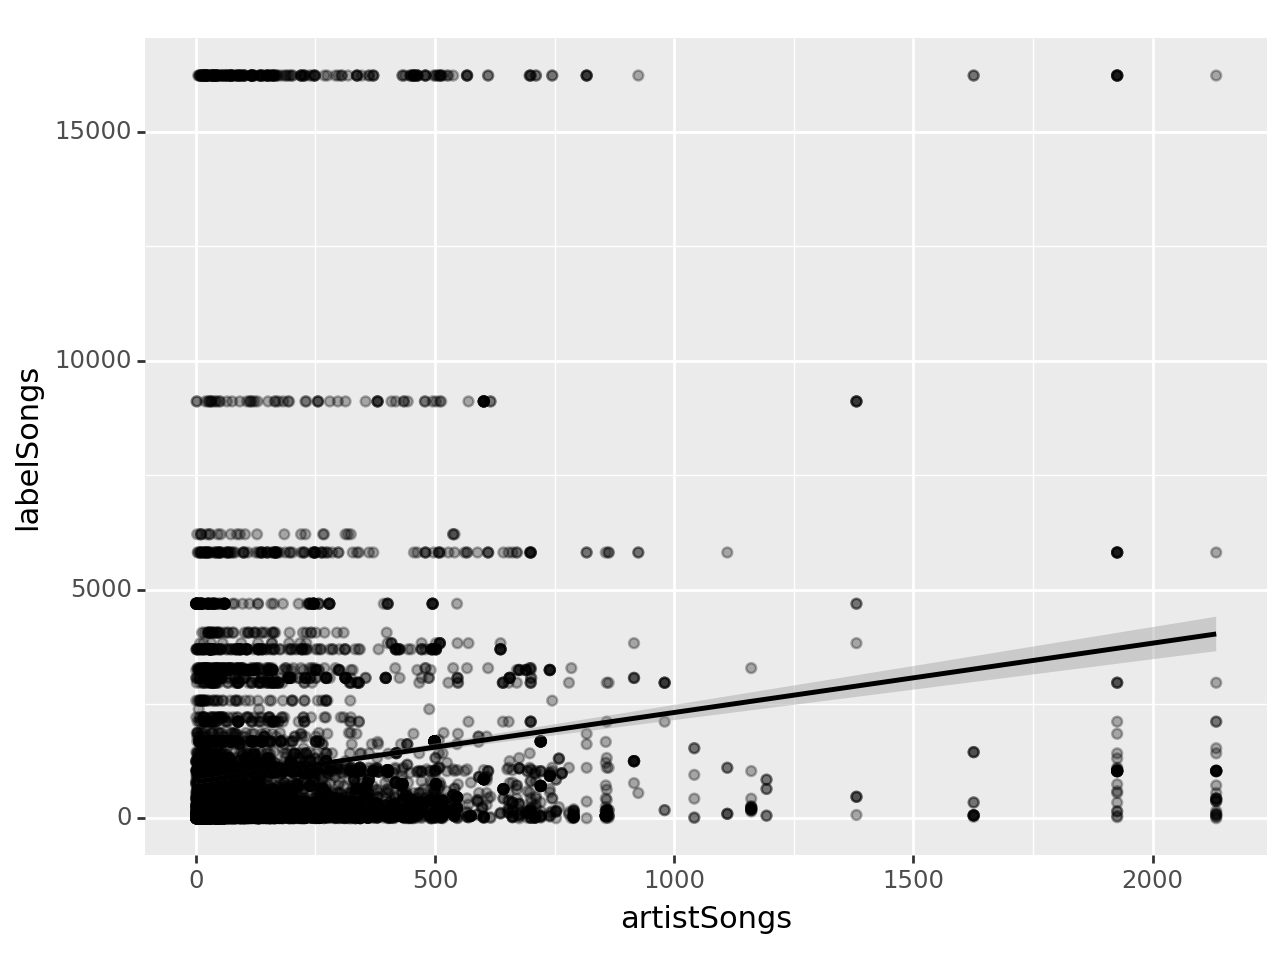

<Figure Size: (640 x 480)>

In [30]:
(ggplot(df, aes(x = "artistSongs", y = "labelSongs")) +
   geom_point(alpha = 0.3) +
   geom_smooth(method = "lm"))

### Categorical Variables

As we've previously discussed, the best visualization for a categorical variable is a ***bar chart***.

#### Bar Chart

Unlike charts in `matplotlib`, you do not need to use `value_counts()` when creating bar charts for categorical variables. To draw a bar chart, you can simply use `geom_bar()` as follows:

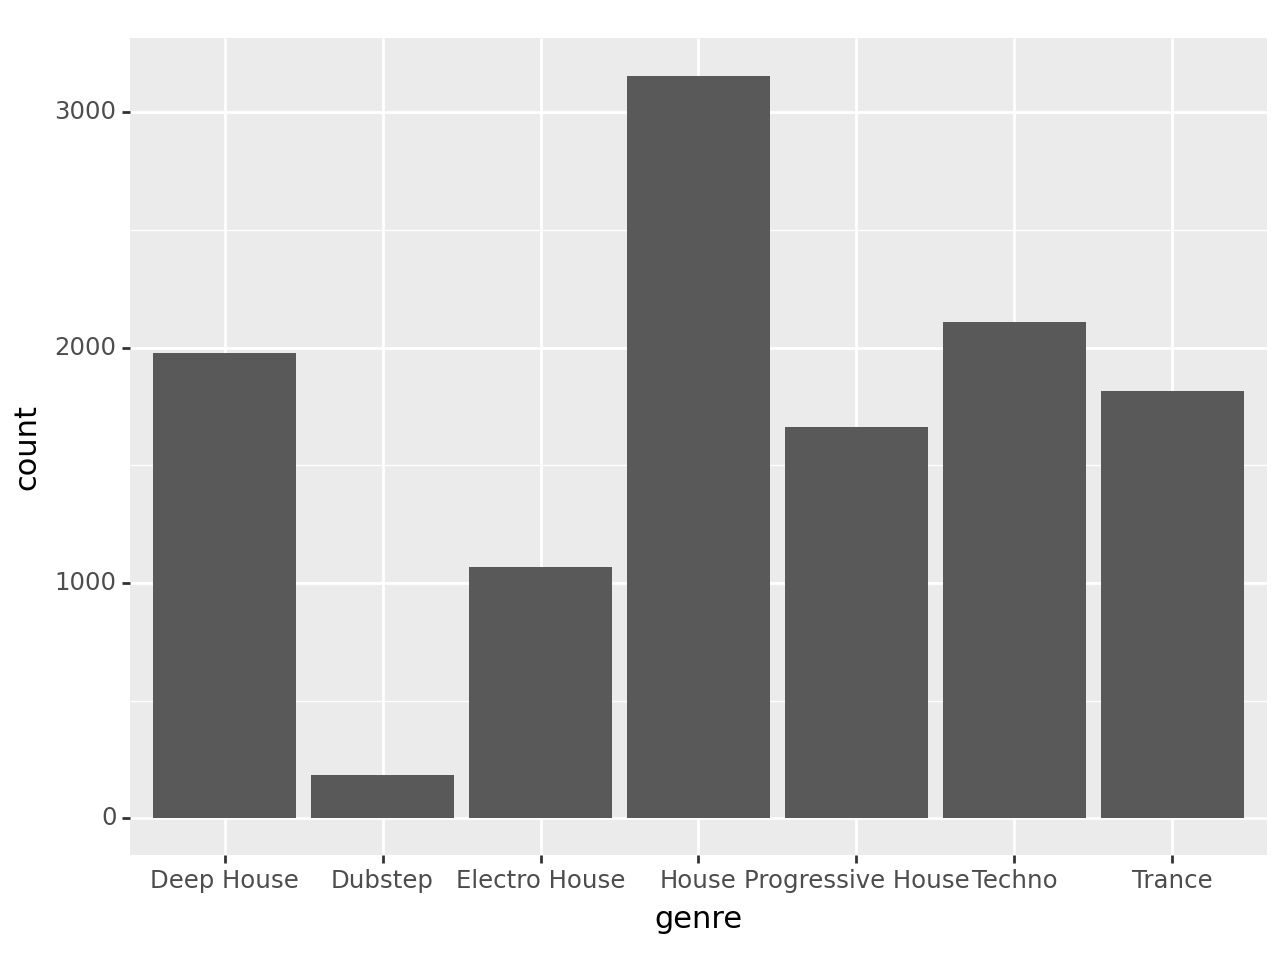

<Figure Size: (640 x 480)>

In [31]:
(ggplot(df, aes(x = "genre")) +
   geom_bar())

What if you want to display the relationship between 2 categorical variables? Once again, a stacked bar chart makes the most sense. You can do this by adding a `fill=` attribute:

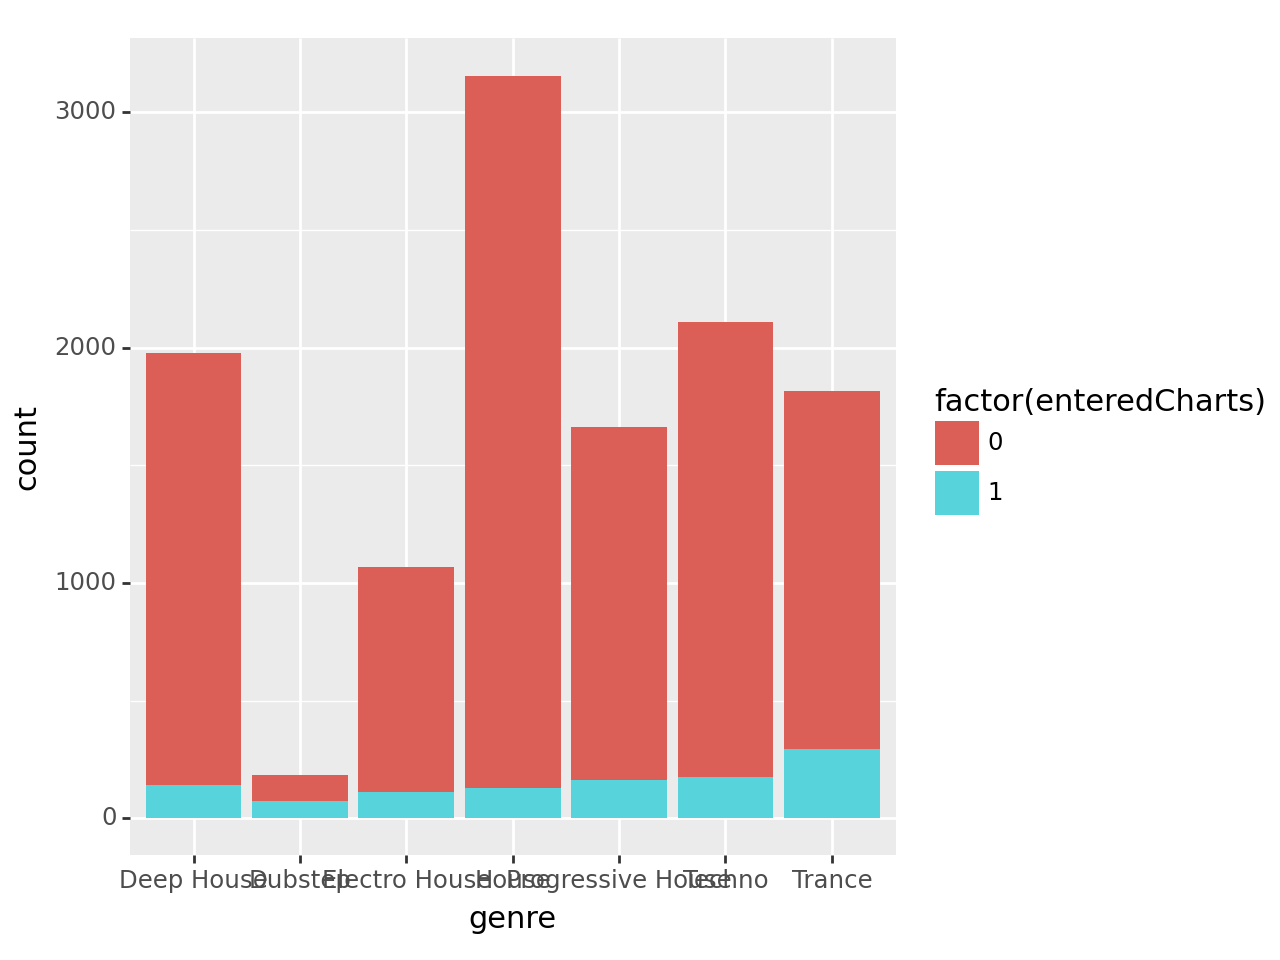

<Figure Size: (640 x 480)>

In [32]:
(ggplot(df, aes(x = "genre", fill = "factor(enteredCharts)")) +
   geom_bar())

Notice that the x-axis labels are now overlapping, making them hard to read. See if you can figure out how to fix this based on code we've already reviewed:

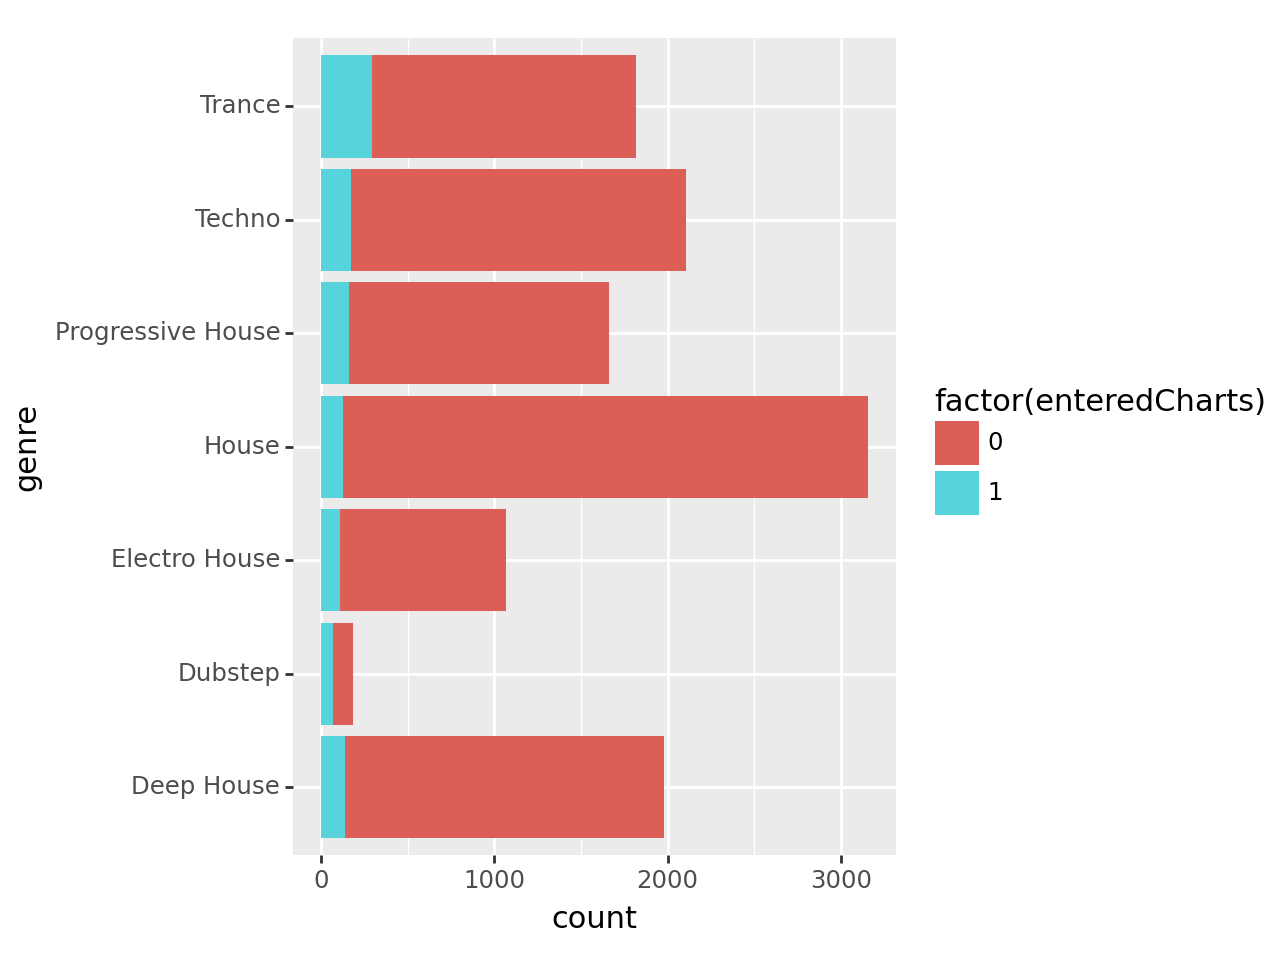

<Figure Size: (640 x 480)>

In [33]:
(ggplot(df, aes(x = "genre", fill = "factor(enteredCharts)")) +
   geom_bar() +
   coord_flip())

Because of the imbalance between genre categories, it's difficult to compare the proportion of songs that did or did not enter the charts. To display the proportions instead of counts and to extend each bar to 100%, use `position = "fill"` in the `geom_bar()` layer:

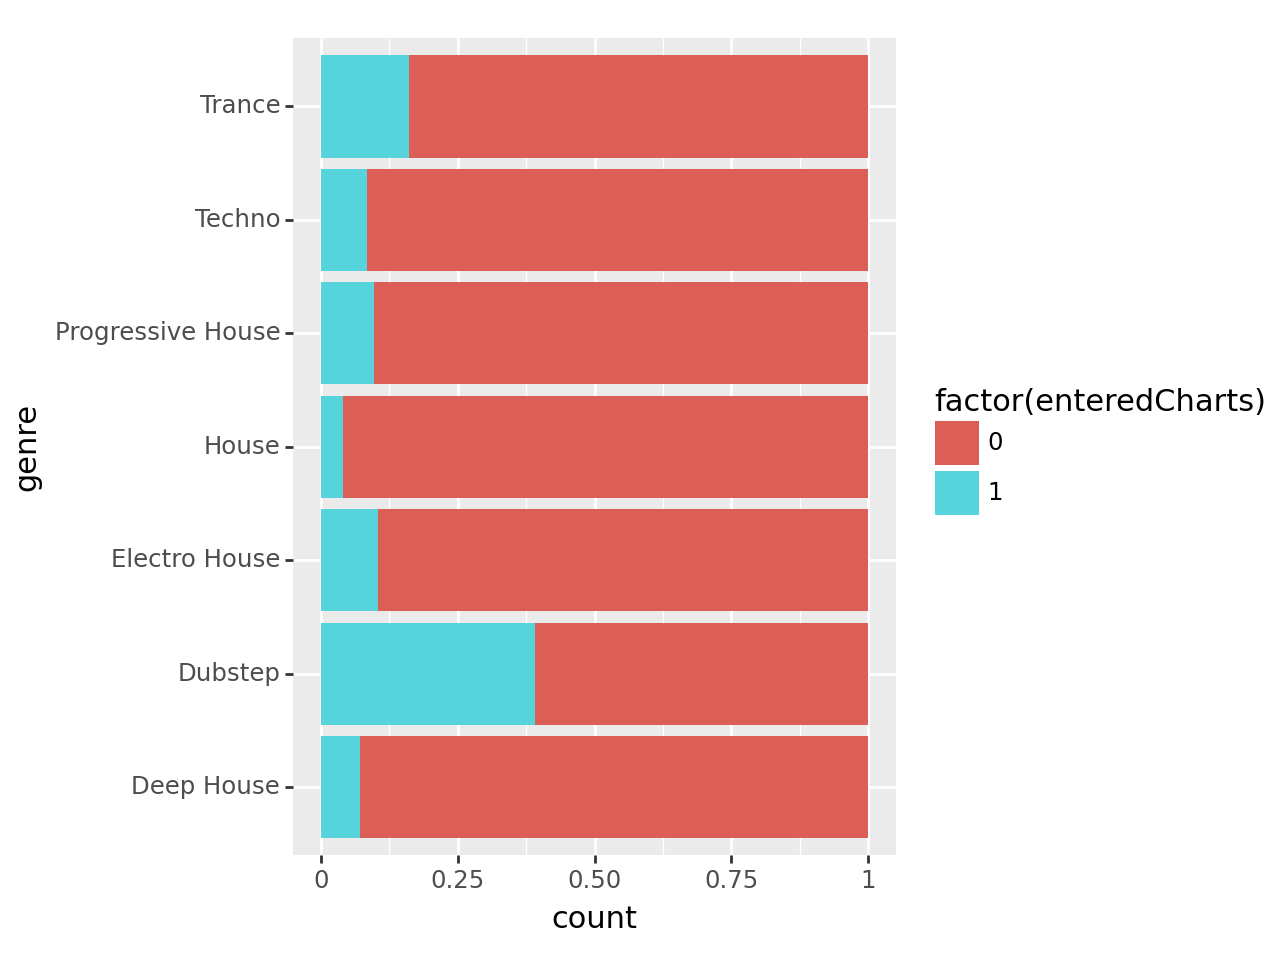

<Figure Size: (640 x 480)>

In [34]:
(ggplot(df, aes(x = "genre", fill = "factor(enteredCharts)")) +
   geom_bar(position = "fill") +
   coord_flip())

Relatively speaking, which genre has the highest proportion of songs that entered the charts?

Now you try...draw a bar chart showing only 2 bars for whether or not a song entered the charts, segmented by genre, and make sure your bars extend to 100%:

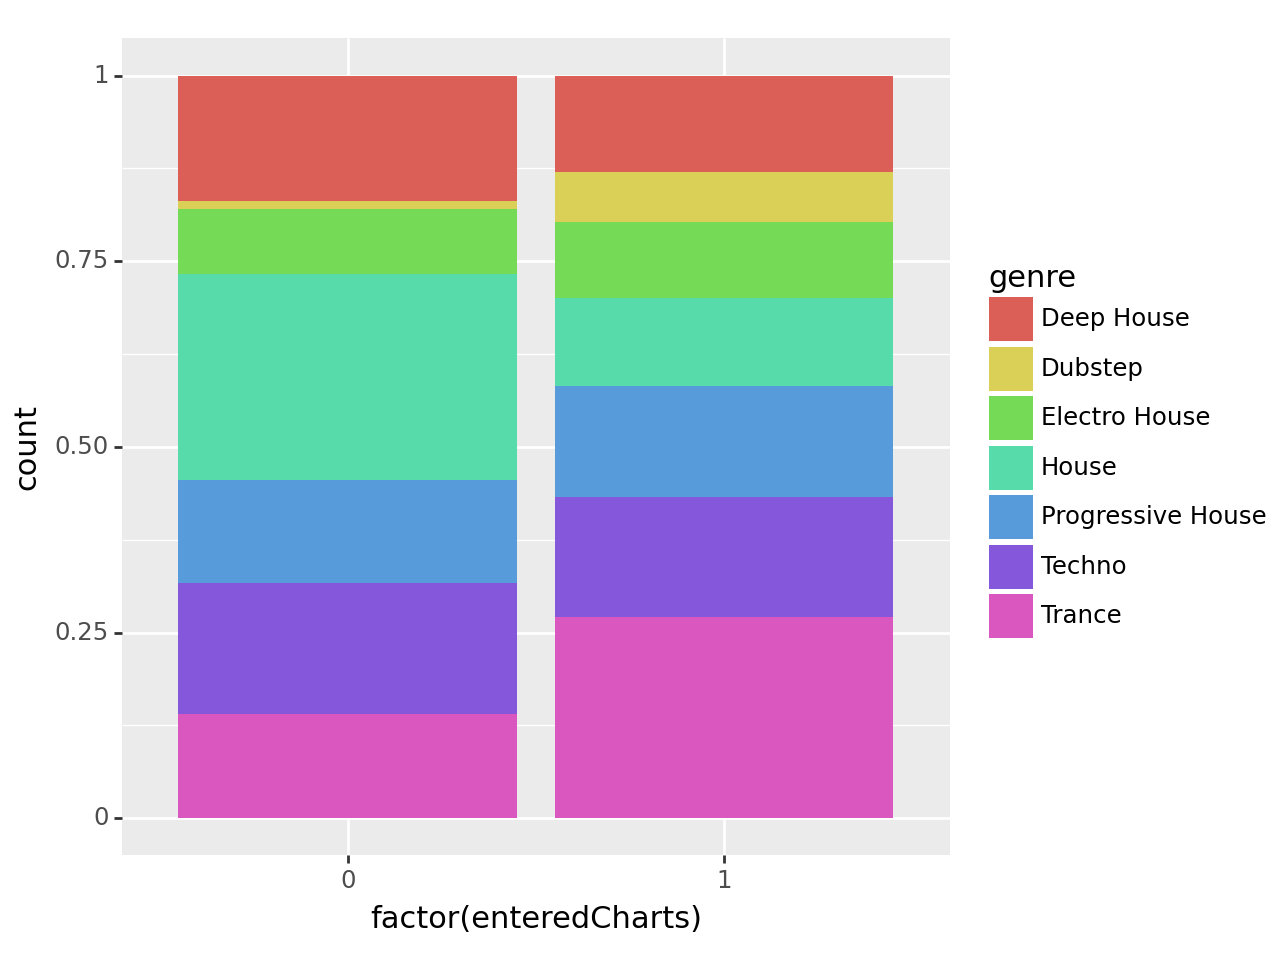

<Figure Size: (640 x 480)>

In [35]:
(ggplot(df, aes(x = "factor(enteredCharts)", fill = "genre")) +
   geom_bar(position = "fill"))

## Saving Your Graph

You can save your graph as an image file by using `ggsave()`.

First, save your graph to a variable:

In [36]:
p = (ggplot(df, aes(x = "genre")) +
   geom_bar())

Then, use `ggsave()`, with the first parameter being the name of your variable and the second parameter being the name you're giving your image file in quotes. For example:

In [37]:
ggsave(p, "examplegraph.png")

/opt/tljh/user/lib/python3.10/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 6.4 x 4.8 in image.
/opt/tljh/user/lib/python3.10/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: examplegraph.png


Note: you need to include the file extension (e.g., .png, .jpg, .svc).

## Practice

Read in the "creditCardDefaultReduced.csv" data file and call it `df2`:

In [38]:
df2 = pd.read_csv("creditCardDefaultReduced.csv")
df2

,Limit_Bal,Education,Marriage,Age,Pay_0,Bill_Amt1,Pay_Amt1,Payment,Card
0,20000,University,married,24,Delay2,3913,0,Missed,Normal
1,120000,University,single,26,ontime,2682,0,Missed,Normal
2,90000,University,single,34,Delay0,29239,1518,Paid,Normal
3,50000,University,married,37,Delay0,46990,2000,Paid,Normal
4,50000,University,married,57,ontime,8617,2000,Paid,Gold
...,...,...,...,...,...,...,...,...,...
29995,220000,High school,married,39,Delay0,188948,8500,Paid,Gold
29996,150000,High school,single,43,ontime,1683,1837,Paid,Gold
29997,30000,University,single,37,Delay4,3565,0,Missed,Gold
29998,80000,High school,married,41,Delay1,-1645,85900,Missed,Gold


#### 1. Create a histogram of the "Bill_Amt1" variable, using 30 bins:

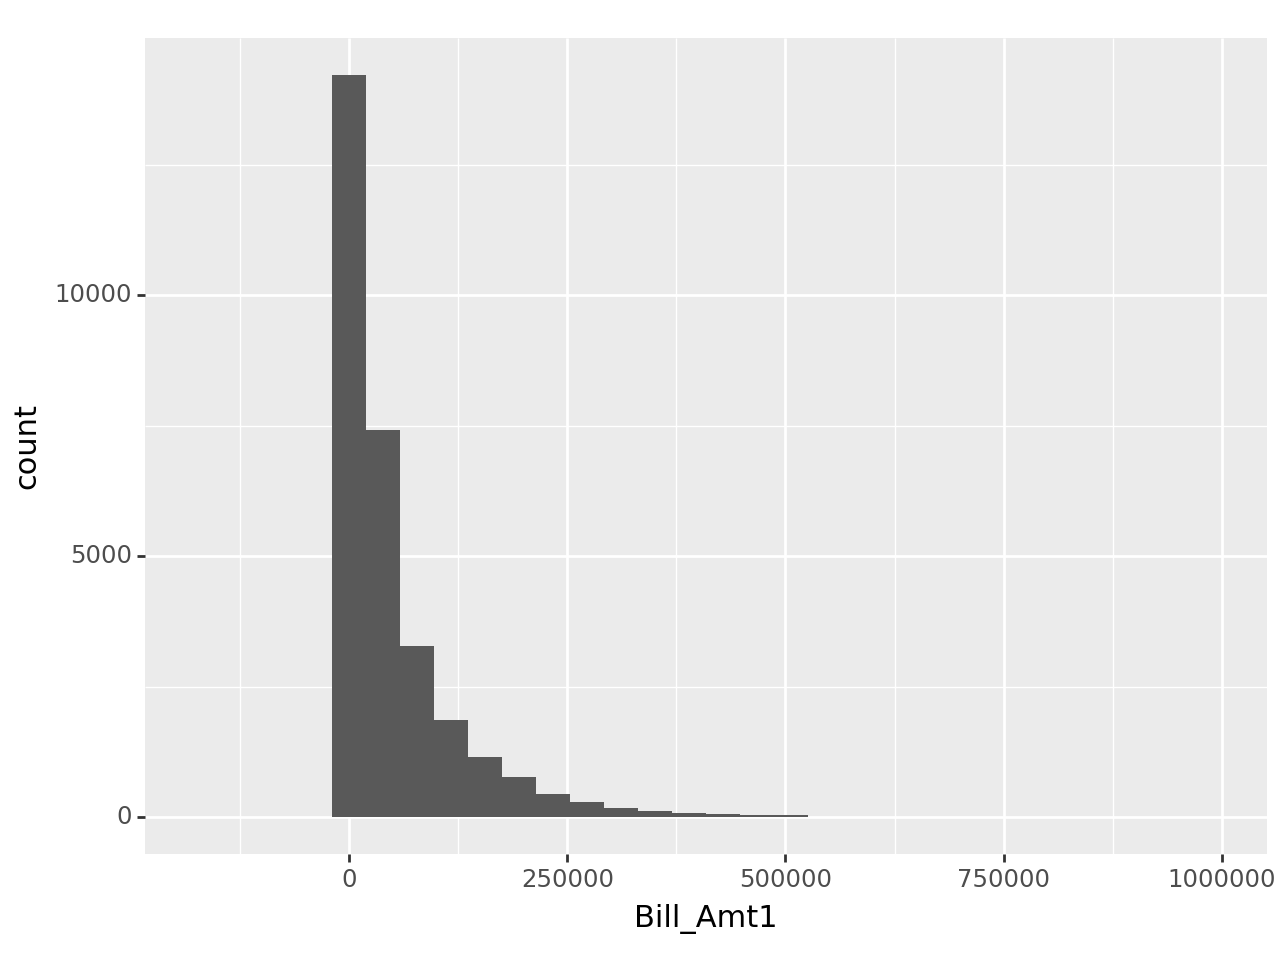

<Figure Size: (640 x 480)>

In [39]:
(ggplot(df2, aes(x = "Bill_Amt1")) +
   geom_histogram(bins = 30))

Are there any anomalies in the data you notice from this histogram?

#### 2. Draw a side-by-side boxplot, showing the distribution of "Limit_Bal" broken out by "Education". Display the boxplots horizontally:

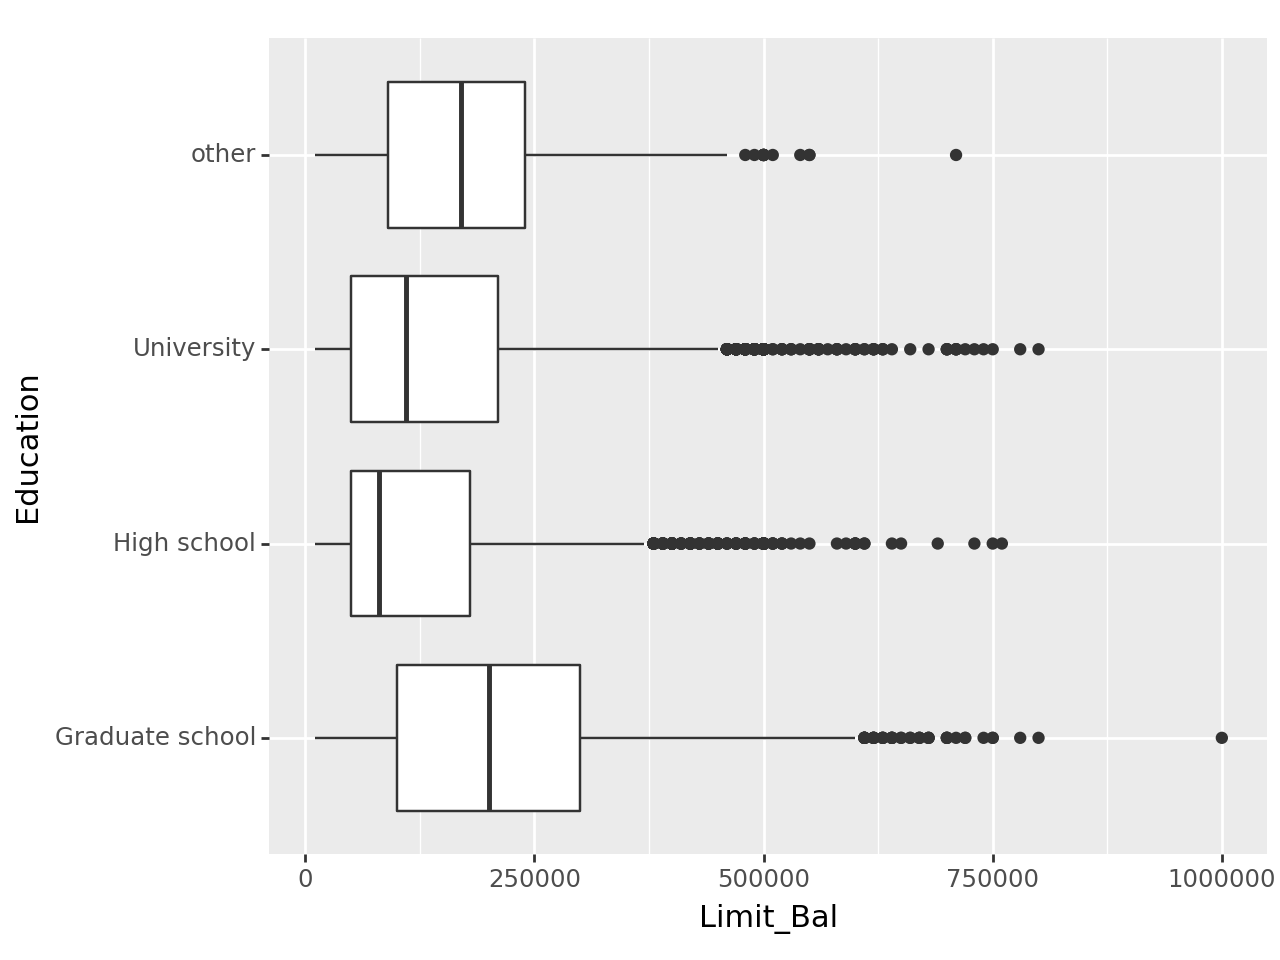

<Figure Size: (640 x 480)>

In [40]:
(ggplot(df2, aes(y = "Limit_Bal", x = "Education")) +
   geom_boxplot() +
   coord_flip())

#### 3. Create a scatter plot of "Age" (x) vs. "Limit_Bal" (y) using color to show the differences between "Education" levels...also include regression lines (use an alpha = 0.2):

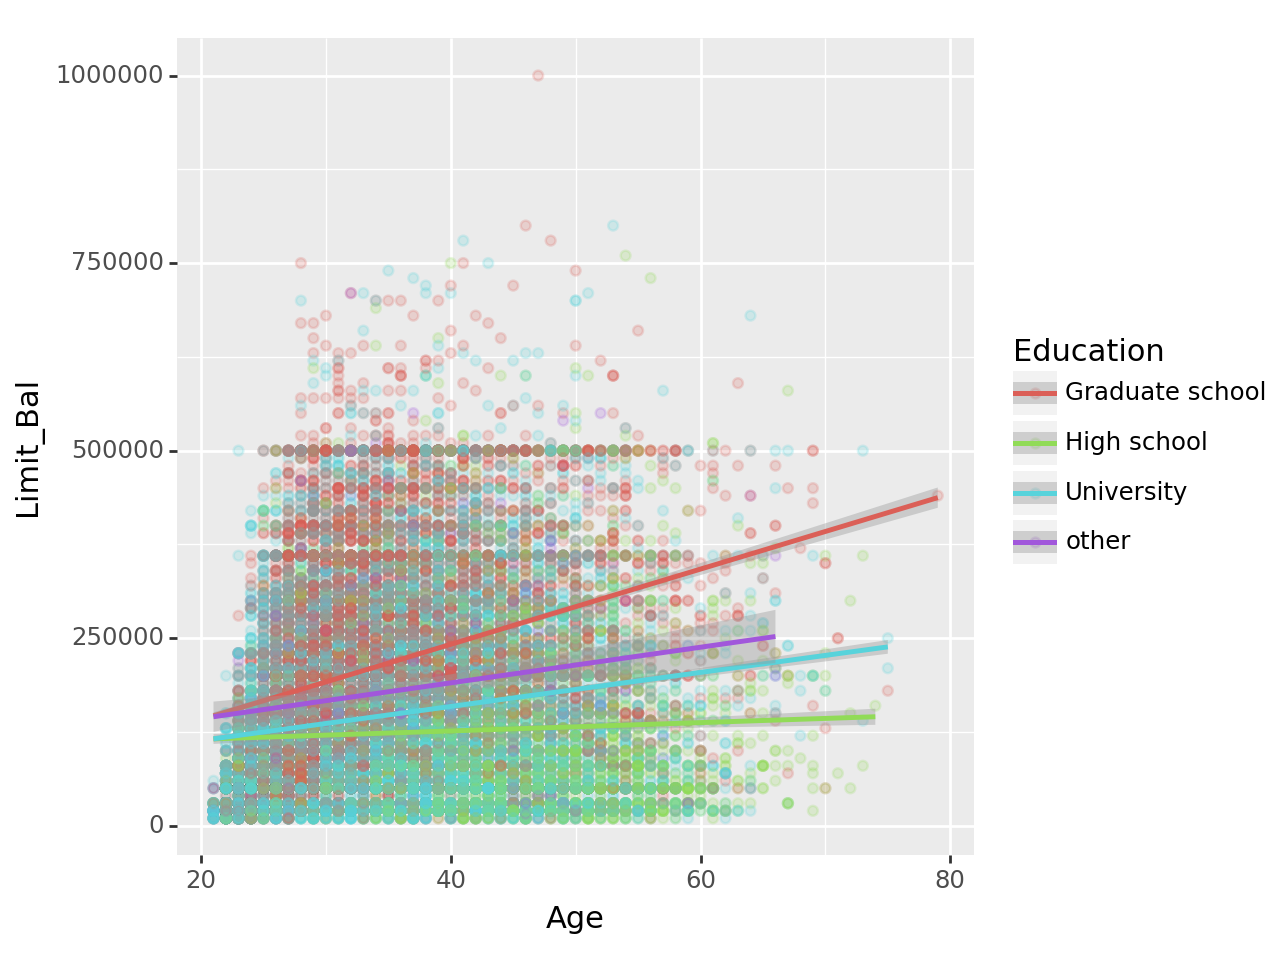

<Figure Size: (640 x 480)>

In [41]:
(ggplot(df2, aes(x = "Age", y = "Limit_Bal", color = "Education")) +
   geom_point(alpha = 0.2) +
   geom_smooth(method = "lm"))

What conclusions could you make when comparing the regression line for high schoolers vs. those who attended graduate school?

#### 4. Create a stacked bar chart of "Education" broken out by whether or not someone paid ("Payment"). Make sure the bars extend to 100%:

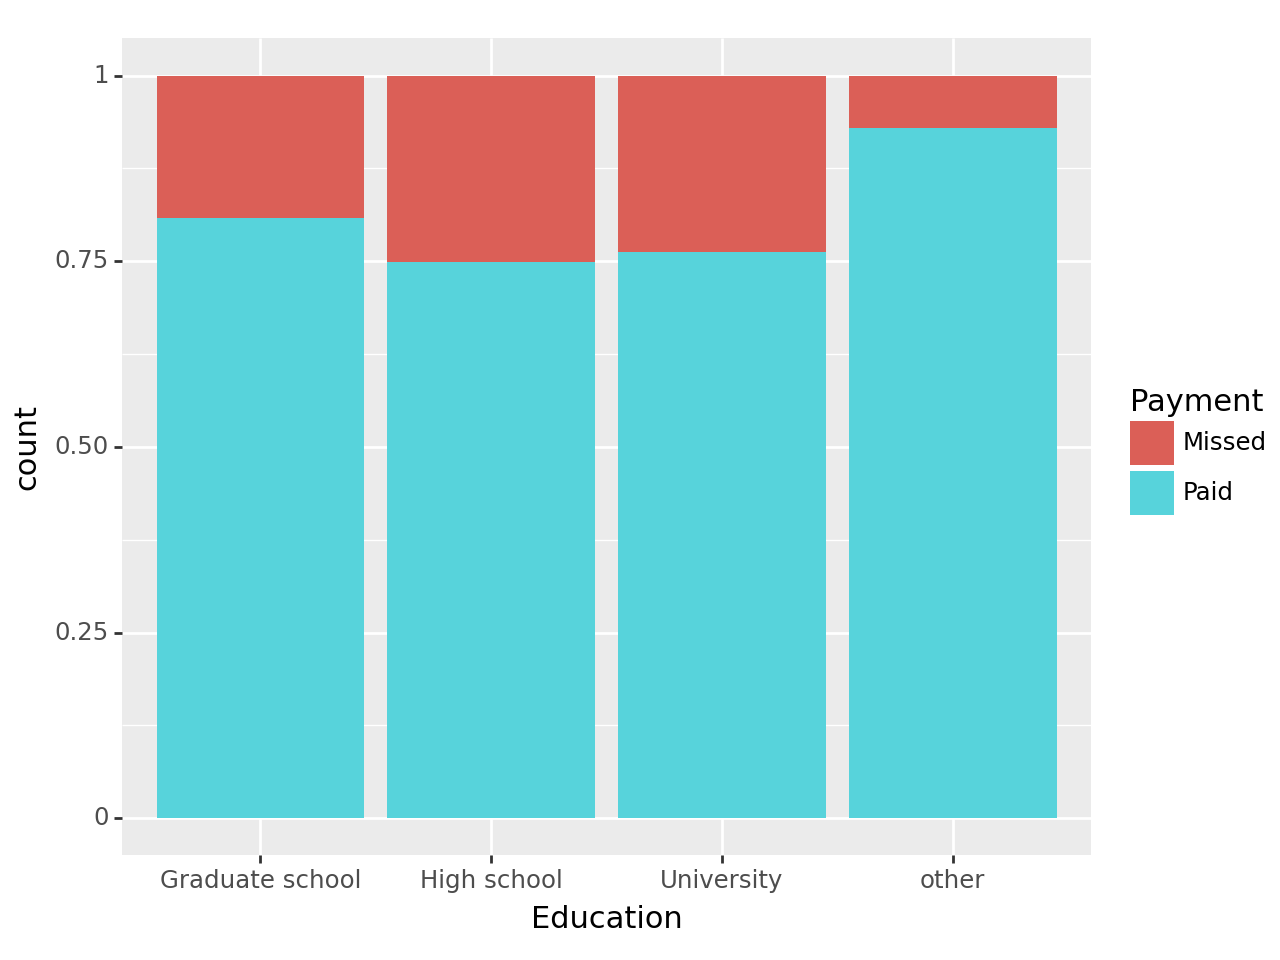

<Figure Size: (640 x 480)>

In [42]:
(ggplot(df2, aes(x = "Education", fill = "Payment")) +
   geom_bar(position = "fill"))

#### 5. Now save the previous graph in an image file called "mygraph.png":

In [43]:
p2 = (ggplot(df2, aes(x = "Education", fill = "Payment")) +
   geom_bar(position = "fill"))

ggsave(p2, "mygraph.png")

/opt/tljh/user/lib/python3.10/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 6.4 x 4.8 in image.
/opt/tljh/user/lib/python3.10/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: mygraph.png
